# Defense figures and tables for the GaussianNB chains

One notebook that regenerates every figure and table of the paper *Improving and Verifying a Gaussian Naive Bayes EEG Command Decoder Across PyTorch, TensorFlow and JAX* from the saved artifacts and the notebook feature caches, in the order of the paper. Each section is labelled with the paper's figure or table number and names the output file written next to this notebook. The computations live in `make_defense_figures.py` (one function per output); this notebook calls them, so `python make_defense_figures.py` and this notebook produce the same files.

Needs: `Data_clean` (for the dataset table and one latency capture), `predictions_local/feature_cache/`, the PyTorch artifacts in `../pytorch/` and the TensorFlow and JAX pickles. Run time about an hour (the permutation null, the latency benchmarks and the original random forest take longest). Run from this folder.

In [1]:
import sys, time, json
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display
sys.path.insert(0, str(Path.cwd()))
import make_defense_figures as M
HERE = M.HERE
def show(png): display(Image(filename=str(HERE / png), width=900))
def table(csv, floatfmt="{:.3f}"):
    df = pd.read_csv(HERE / csv)
    return df.style.format({c: floatfmt for c in df.select_dtypes("number").columns if df[c].dtype.kind == "f"}).hide(axis="index")
t_start = time.perf_counter()
summary = {}

## Shared inputs: the feature caches, the notebook split and the two chains' predictions

Every result below uses the same 12,089 windows and the notebook's own split (one fold of a stratified group split by recording, seed 42: 9,670 training and 2,419 test windows).

In [2]:
data = M.load_caches()
train, test = M.notebook_split(data["X_sub"], data["y"], data["groups"])
print(f"{len(data['y'])} windows, {len(np.unique(data['groups']))} recordings, {len(np.unique(data['parts']))} participants; "
      f"notebook split: {train.sum()} train / {test.sum()} test windows")
chain_imp, chain_sub, logp_imp, logp_sub = M.chain_predictions(data, train, test)
logp_by_chain = {"Improved global chain": logp_imp, "Subject-specific chain": logp_sub}

12089 windows, 883 recordings, 18 participants; notebook split: 9670 train / 2419 test windows


## Table 3.1 and Figure 3.1: what the loader keeps from Data_clean

Outputs: `defense_dataset.csv`, `defense_dataset.png`. Reloads Data_clean through the shared loader (slow); pass `skip_load=True` to reuse the cached counts.

[defense] Data_clean reloaded in 4 s: 1394 recordings, 432 skipped


[defense] wrote defense_dataset.csv


[defense] wrote defense_dataset.png


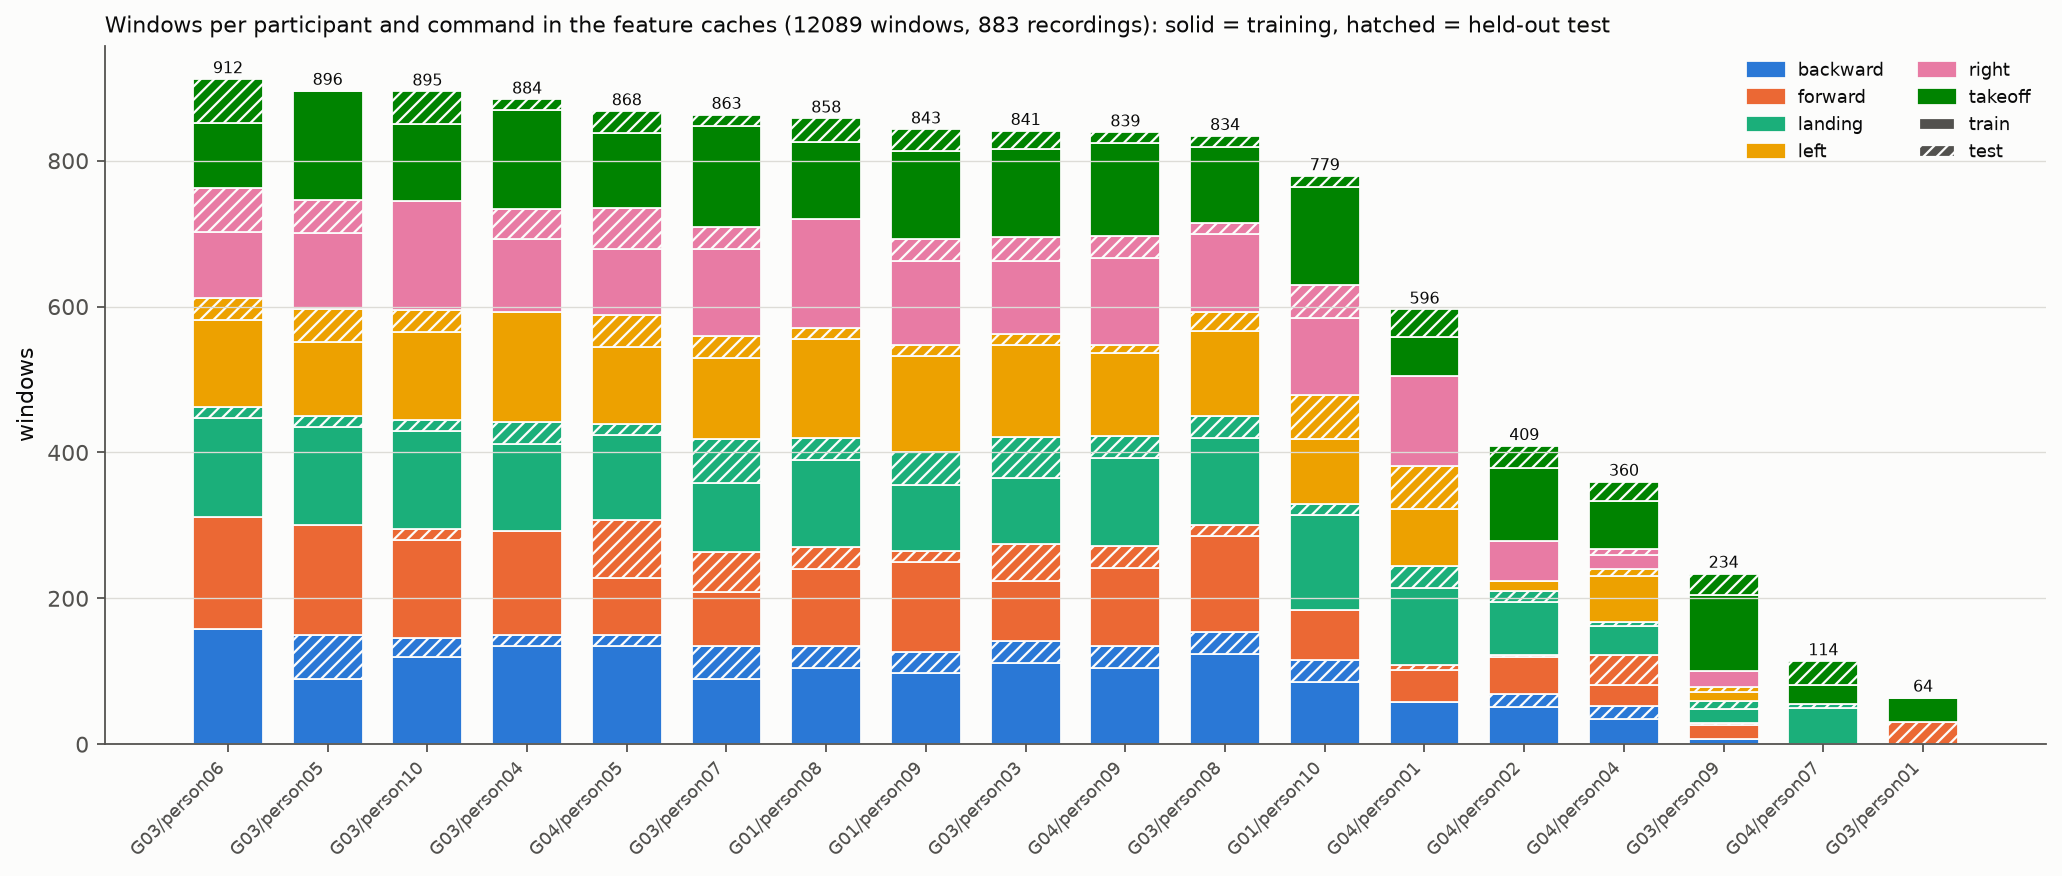

Quantity,Value,Detail
Files under Data_clean,3648,eeg_data.load_recordings
Named OpenBCI recordings found,1826,eeg_data.load_recordings
"Recordings loaded (16ch_125hz, 15 channels)",1394,eeg_data.load_recordings
"Recordings skipped (other board, unreadable or unlabelled)",432,422 of another board
2 s blocks assessed,6703,signal_quality policy on the kept channels
2 s blocks kept,3249,48.5 %
Recordings with usable data,883,at least one kept block
Participants with usable data,18 of 23,"none usable: G03/person02, G04/person03, G04/person06, G04/person08, G04/person10"
Windows in the feature caches,12089,"128 samples (1.024 s), stride 64"
Recordings in the caches,883,one contiguous block of windows each


In [3]:
summary["dataset"] = M.dataset_figure_and_table(data, train, test, chain_imp, skip_load=False)
show("defense_dataset.png"); table("defense_dataset.csv")

## Figure 6.1: confusion matrices of the three chains on the same held-out windows

Output: `defense_progression_confusion_matrices.png` (the original chain is rebuilt from the hybrid cache with scikit-learn and fitted on the training windows only). Also written here: the per-class metrics and the two deployed chains' confusion matrices (`defense_per_class_metrics.csv`, `defense_confusion_matrices.png`).

[defense] improved global chain on the notebook's test windows: threshold rule 0.4986, argmax 0.4948; subject-specific 0.8458 (n = 2419)


[defense] wrote defense_per_class_metrics.csv


[defense] wrote defense_confusion_matrices.png, defense_improved_global_confusion_matrix.png


[defense] original chain rebuilt in 2 s: PCA 62 dims, accuracy 0.2604 (notebook fold 1: 0.260)


[defense] wrote defense_progression_confusion_matrices.png


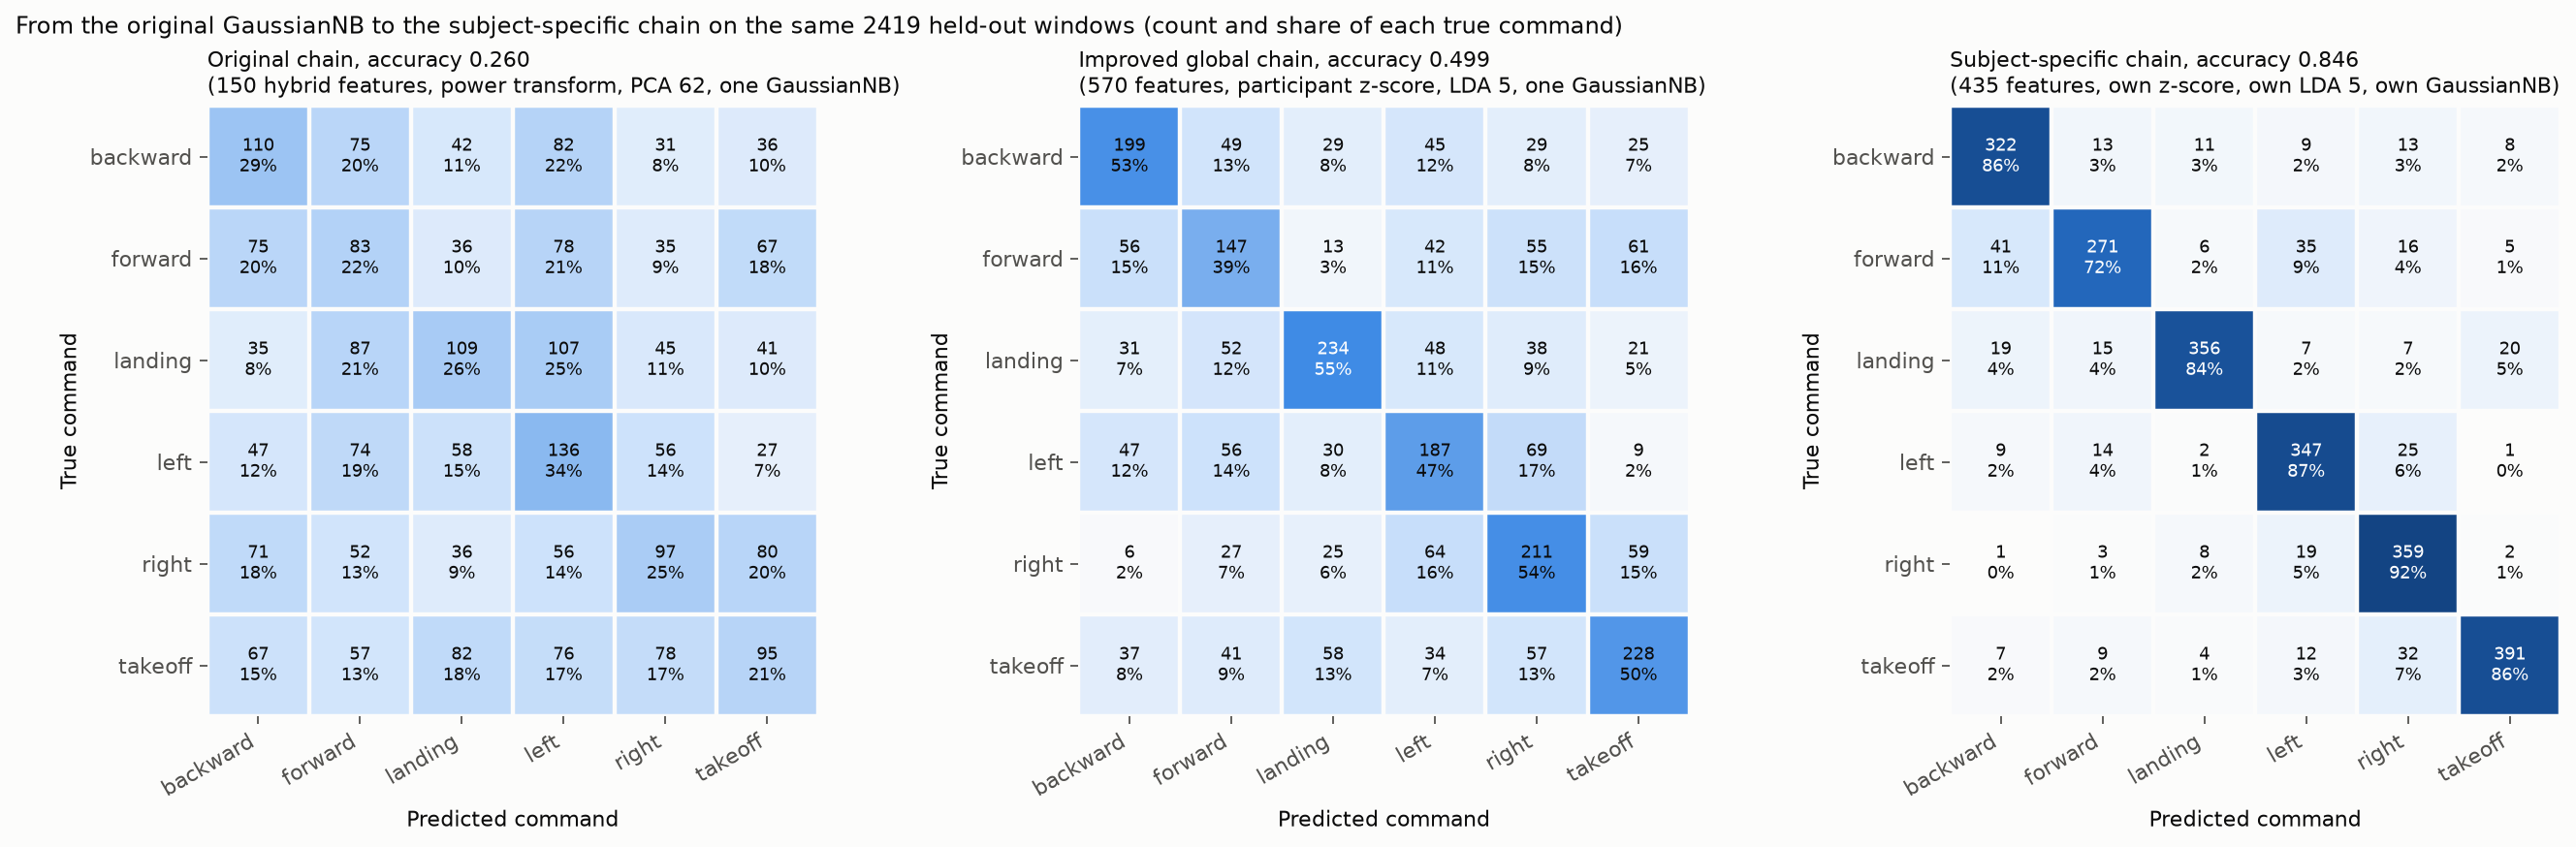

Chain,Class,Precision,Recall,F1,Support
"Improved global chain (threshold rule, as deployed)",backward,0.529,0.529,0.529,376
"Improved global chain (threshold rule, as deployed)",forward,0.395,0.393,0.394,374
"Improved global chain (threshold rule, as deployed)",landing,0.602,0.552,0.576,424
"Improved global chain (threshold rule, as deployed)",left,0.445,0.470,0.457,398
"Improved global chain (threshold rule, as deployed)",right,0.460,0.538,0.496,392
"Improved global chain (threshold rule, as deployed)",takeoff,0.566,0.501,0.531,455
"Improved global chain (threshold rule, as deployed)",all (accuracy / macro-F1 / balanced acc),0.499,0.497,0.497,2419
Improved global chain (argmax),backward,0.514,0.574,0.543,376
Improved global chain (argmax),forward,0.388,0.404,0.396,374
Improved global chain (argmax),landing,0.599,0.512,0.552,424


In [4]:
acc = M.confusion_and_per_class(data, train, test, logp_imp, logp_sub, chain_imp)
window_pred = {"Improved global chain": acc["pred_imp"], "Subject-specific chain": acc["pred_sub"]}
summary["progression"] = M.progression_confusions(data, train, test, acc["pred_imp"], acc["pred_sub"])
show("defense_progression_confusion_matrices.png"); table("defense_per_class_metrics.csv")

## Table 6.1: accuracy of the three chains on the notebook split (intervals, kappa, McNemar, per-fold tests)

Output: `defense_statistics.csv`. The protocol rows of the paper's table come from cells 15 and 19 of the main notebook (`../pytorch/gaussiannb_improved_vs_baseline_summary.csv`); the gated row from `defense_vote_gate.csv` below.

In [5]:
summary["statistics"] = M.statistics_table(data, test, logp_by_chain, window_pred)
table("defense_statistics.csv", "{:.4f}")

[defense] wrote defense_statistics.csv


Statistic,Chain,Estimate,95 % low,95 % high,n,Detail
Window accuracy,Improved global chain,0.4986,0.4786,0.5185,2419,Wilson interval
Per-recording accuracy,Improved global chain,0.6250,0.5515,0.6931,176,Wilson interval
"Gated accuracy (4 of 5, accepted decisions)",Improved global chain,0.7537,0.7213,0.7835,735,coverage 0.426 of 1725 decisions
Cohen's kappa (windows),Improved global chain,0.3982,nan,nan,2419,"0 = chance agreement, 1 = perfect"
Window accuracy,Subject-specific chain,0.8458,0.8309,0.8596,2419,Wilson interval
Per-recording accuracy,Subject-specific chain,0.9034,0.8508,0.9388,176,Wilson interval
"Gated accuracy (4 of 5, accepted decisions)",Subject-specific chain,0.9422,0.9290,0.9531,1453,coverage 0.842 of 1725 decisions
Cohen's kappa (windows),Subject-specific chain,0.8149,nan,nan,2419,"0 = chance agreement, 1 = perfect"
"McNemar exact test, Subject-specific chain vs Improved global chain (windows)",both,0.0000,nan,nan,2419,"exact p = 2.6e-172; Improved global chain right and Subject-specific chain wrong: 99, the reverse: 939; chi-square with continuity correction 678.2 (p = 1.7e-149)"
"Protocol A, window accuracy per fold: improved minus baseline",both,0.2365,0.2017,0.2613,5,"range over the 5 folds; Wilcoxon signed-rank p = 0.0625 (the smallest two-sided p with 5 folds is 0.0625); folds [0.236, 0.244, 0.261, 0.202, 0.24]"


## Figure 6.6: vote-gate operating points

Output: `defense_vote_gate.csv`, `defense_vote_gate.png` (coverage against accuracy of accepted decisions for k of 5 agreeing votes; the deployed point is 4 of 5).

[defense] wrote defense_vote_gate.csv


[defense] wrote defense_vote_gate.png


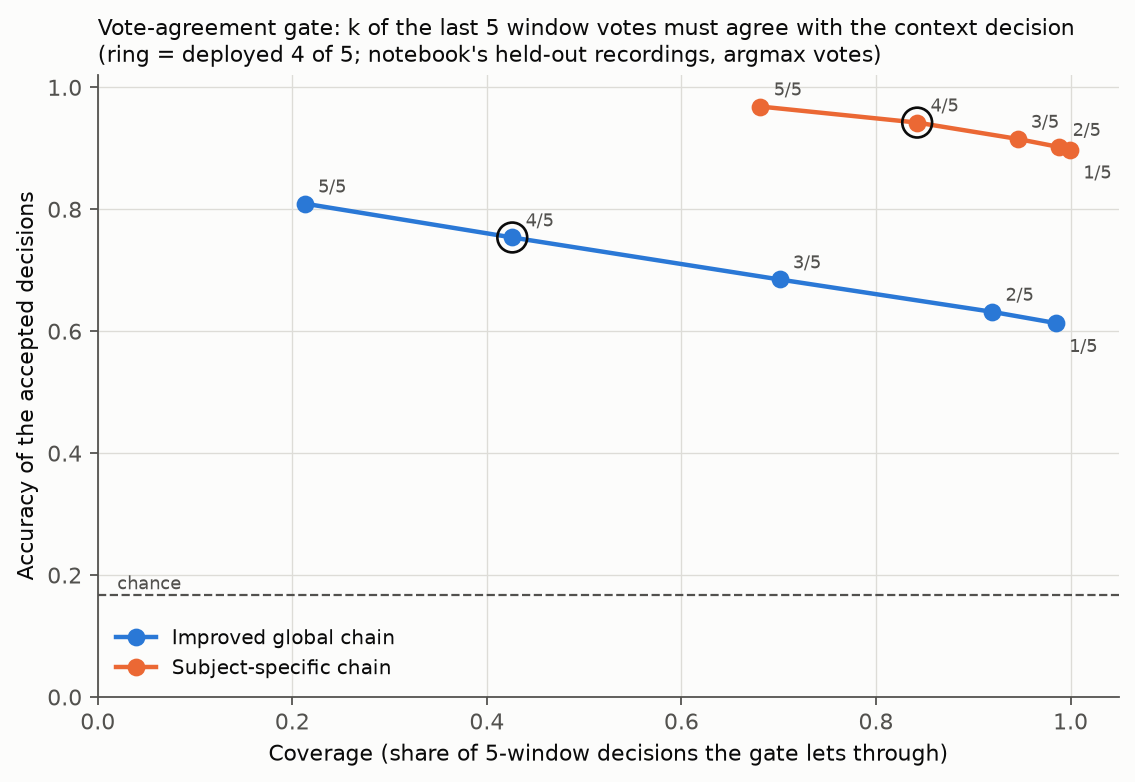

Chain,Agreement needed,Coverage,Accuracy of accepted decisions,Decisions,Accepted,Deployed
Improved global chain,1 of 5,0.985,0.613,1725,1699,nan
Improved global chain,2 of 5,0.919,0.632,1725,1586,nan
Improved global chain,3 of 5,0.701,0.685,1725,1209,nan
Improved global chain,4 of 5,0.426,0.754,1725,735,yes
Improved global chain,5 of 5,0.213,0.809,1725,367,nan
Subject-specific chain,1 of 5,0.999,0.898,1725,1724,nan
Subject-specific chain,2 of 5,0.988,0.902,1725,1705,nan
Subject-specific chain,3 of 5,0.946,0.915,1725,1631,nan
Subject-specific chain,4 of 5,0.842,0.942,1725,1453,yes
Subject-specific chain,5 of 5,0.681,0.969,1725,1175,nan


In [6]:
gate = M.vote_gate(data, test, logp_by_chain)
summary["vote_gate_deployed"] = gate[gate["Deployed"] == "yes"].drop(columns=["Deployed"]).to_dict("records")
show("defense_vote_gate.png"); table("defense_vote_gate.csv")

## Table 6.4: information transfer rate at three decision levels

Output: `defense_itr.csv` (Wolpaw's bits per decision and bits per minute, scaled by the coverage for the gated rows).

In [7]:
summary["itr"] = M.itr_table(data, test, logp_by_chain, window_pred)
table("defense_itr.csv")

[defense] wrote defense_itr.csv


Chain,Decision,Seconds per decision,Accuracy,Coverage,Bits per decision,Bits per minute,n
Improved global chain,single window (1.02 s),1.024,0.499,1.000,0.421,24.647,2419
Improved global chain,5-window context (3.07 s),3.072,0.609,1.000,0.711,13.882,1725
Improved global chain,"gated context, 4 of 5 votes (3.07 s)",3.072,0.754,0.426,1.208,10.052,735
Subject-specific chain,single window (1.02 s),1.024,0.846,1.000,1.607,94.142,2419
Subject-specific chain,5-window context (3.07 s),3.072,0.897,1.000,1.870,36.514,1725
Subject-specific chain,"gated context, 4 of 5 votes (3.07 s)",3.072,0.942,0.842,2.132,35.075,1453


## Table 6.3: confound controls

Output: `defense_confound_controls.csv` (held-out participants, time-only classifier, three-seed label permutation, temporal 60/40 split, half-block separability, adjacent-block error share).

In [8]:
controls = M.confound_controls(data, train, test, acc["pred_sub"], acc["subject"])
summary["confound_controls"] = controls.to_dict("records")
table("defense_confound_controls.csv")

[defense] wrote defense_confound_controls.csv


Control,Classifier,Value,Reference,Reference_meaning,Notebook,Reading
Held-out participants (5-fold by participant),improved global chain,0.184,0.167,chance,0.180,nothing transfers across people
Held-out participants (5-fold by participant),subject-specific chain,0.189,0.167,chance,0.180,nothing transfers across people
"Acquisition time only, no EEG (label of the nearest training window in time)",time of the window,0.885,0.167,chance,0.970,the split lets time alone predict the command
Labels permuted across recordings within participant (3 seeds),subject-specific chain,0.159,0.167,chance,0.150,the chain learns nothing from shuffled labels: no leak through features
"Train on the first 60 % of every command block, test on the last 40 %",subject-specific chain,0.677,0.846,"same chain, notebook split",0.660,accuracy falls with time distance to the training recordings
First half vs second half of the SAME command block,"LDA + GaussianNB, leave-one-recording-out",0.757,0.500,chance (2 classes),0.730,"windows carry the session's drift, not only the command"
Errors of the subject-specific chain landing on the adjacent block in time,subject-specific chain,0.694,0.339,if errors ignored time,0.790,confusions follow the recording order


## Figure 6.3: permutation null of the subject-specific chain

Output: `defense_permutation.png`, `defense_permutation.csv` (100 label permutations within participant; about 9 minutes).

[defense] permutation 20/100 (89 s)


[defense] permutation 40/100 (172 s)


[defense] permutation 60/100 (255 s)


[defense] permutation 80/100 (337 s)


[defense] permutation 100/100 (418 s)


[defense] permutation test: observed 0.8564, null 0.1617 +- 0.0182 (max 0.2089), p = 0.0099 over 100 permutations


[defense] wrote defense_permutation.png


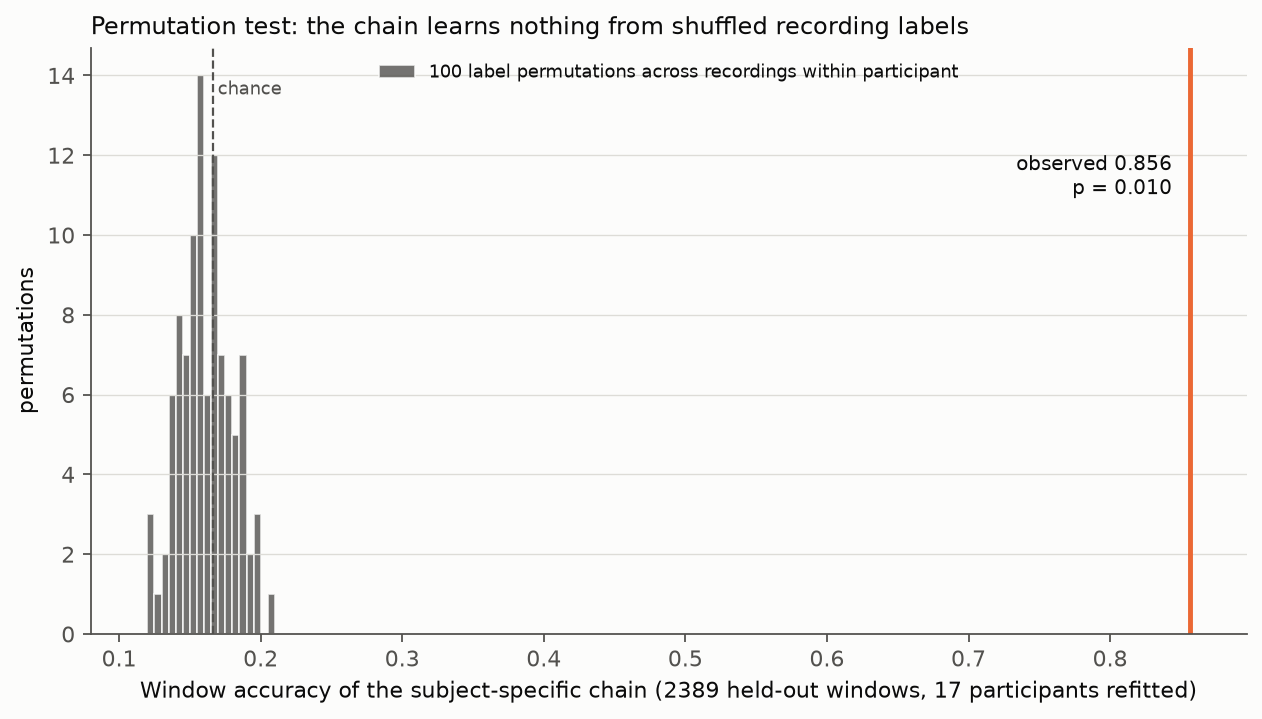

In [9]:
summary["permutation_test"] = M.permutation_test(data, train, test, n_perm=100)
show("defense_permutation.png")

## Figure 6.2: held-out-participant confusion matrix

Output: `defense_heldout_participant_confusion_matrix.png` (protocol C, five-fold by participant, pooled over the folds).

[defense] held-out participants, subject-specific chain: pooled accuracy 0.1884, folds [0.189, 0.181, 0.22, 0.194, 0.161] (notebook mean 0.189)


[defense] wrote defense_heldout_participant_confusion_matrix.png


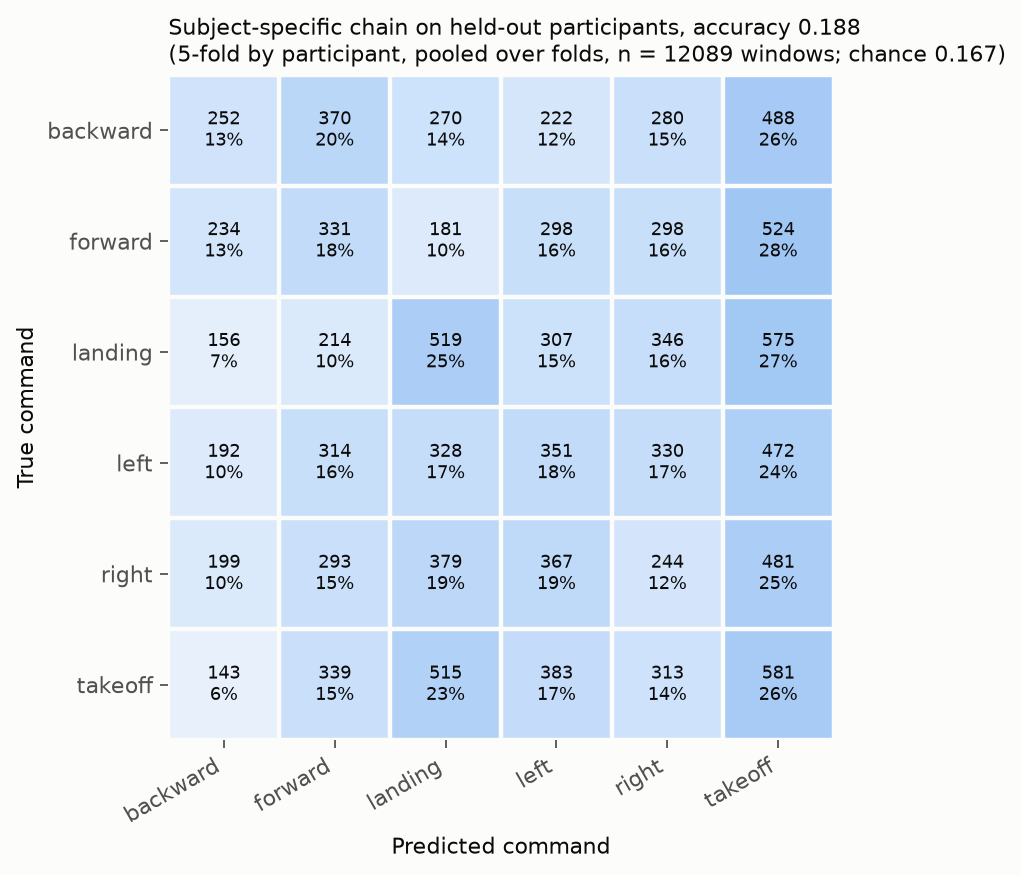

In [10]:
summary["heldout_participants_subject_chain"] = M.heldout_participant_confusion(data)
show("defense_heldout_participant_confusion_matrix.png")

## Figure 6.4: per-participant window accuracy of the subject-specific chain

Output: `defense_per_participant_accuracy.png` (drawn from the notebook's `../pytorch/gaussiannb_subject_specific_per_participant.csv`). The per-participant confusion matrices (`defense_participant_confusion_matrices.png`) are a supplementary output.

[defense] wrote defense_per_participant_accuracy.png (window-weighted accuracy 0.8458)


[defense] wrote defense_participant_confusion_matrices.png (17 participants, G03/person01 (global fallback, 1 command in training, 30 test windows, accuracy 0.00) omitted)


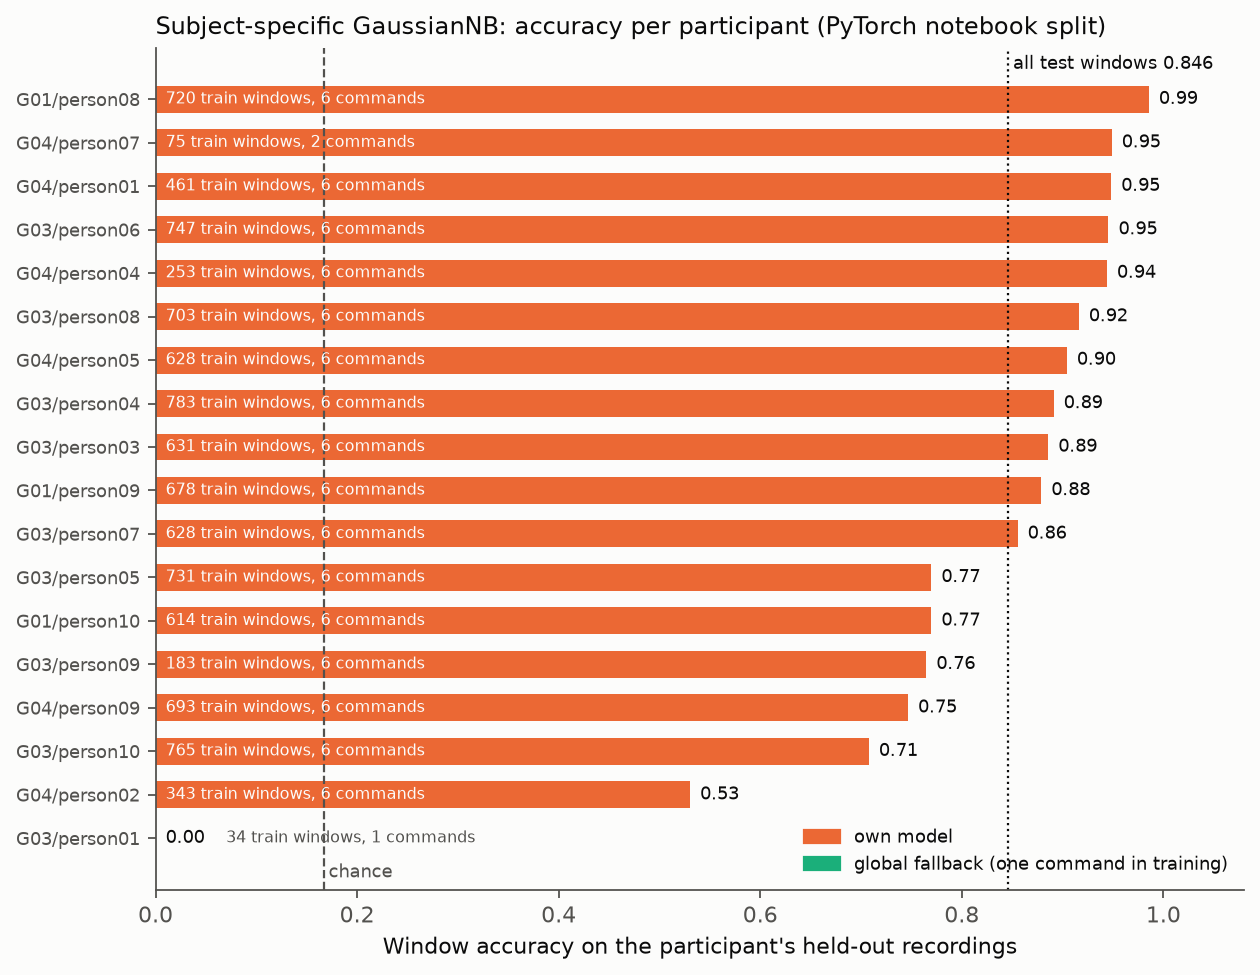

In [11]:
summary["per_participant_weighted_accuracy"] = M.per_participant_chart()
summary["per_participant_accuracy"] = M.participant_confusions(data, test, acc["pred_sub"])
show("defense_per_participant_accuracy.png")

## Figure 6.5: learning curve of the subject-specific chain

Output: `defense_learning_curve_spread.png`, `defense_learning_curve_spread.csv` (each participant's model refitted on the k earliest recordings per command; checked against the notebook's `gaussiannb_subject_learning_curve.csv`).

[defense] learning curve k = 1: 1261 train windows, accuracy 0.5374 (notebook 0.5374)


[defense] learning curve k = 2: 2558 train windows, accuracy 0.6561 (notebook 0.6561)


[defense] learning curve k = 3: 3860 train windows, accuracy 0.6933 (notebook 0.6933)


[defense] learning curve k = 4: 5118 train windows, accuracy 0.7453 (notebook 0.7453)


[defense] learning curve k = 6: 7480 train windows, accuracy 0.8131 (notebook 0.8131)


[defense] learning curve k = 8: 9150 train windows, accuracy 0.8545 (notebook 0.8545)


[defense] learning curve k = all: 9670 train windows, accuracy 0.8458 (notebook 0.8458)


[defense] wrote defense_learning_curve_spread.csv


[defense] wrote defense_learning_curve_spread.png


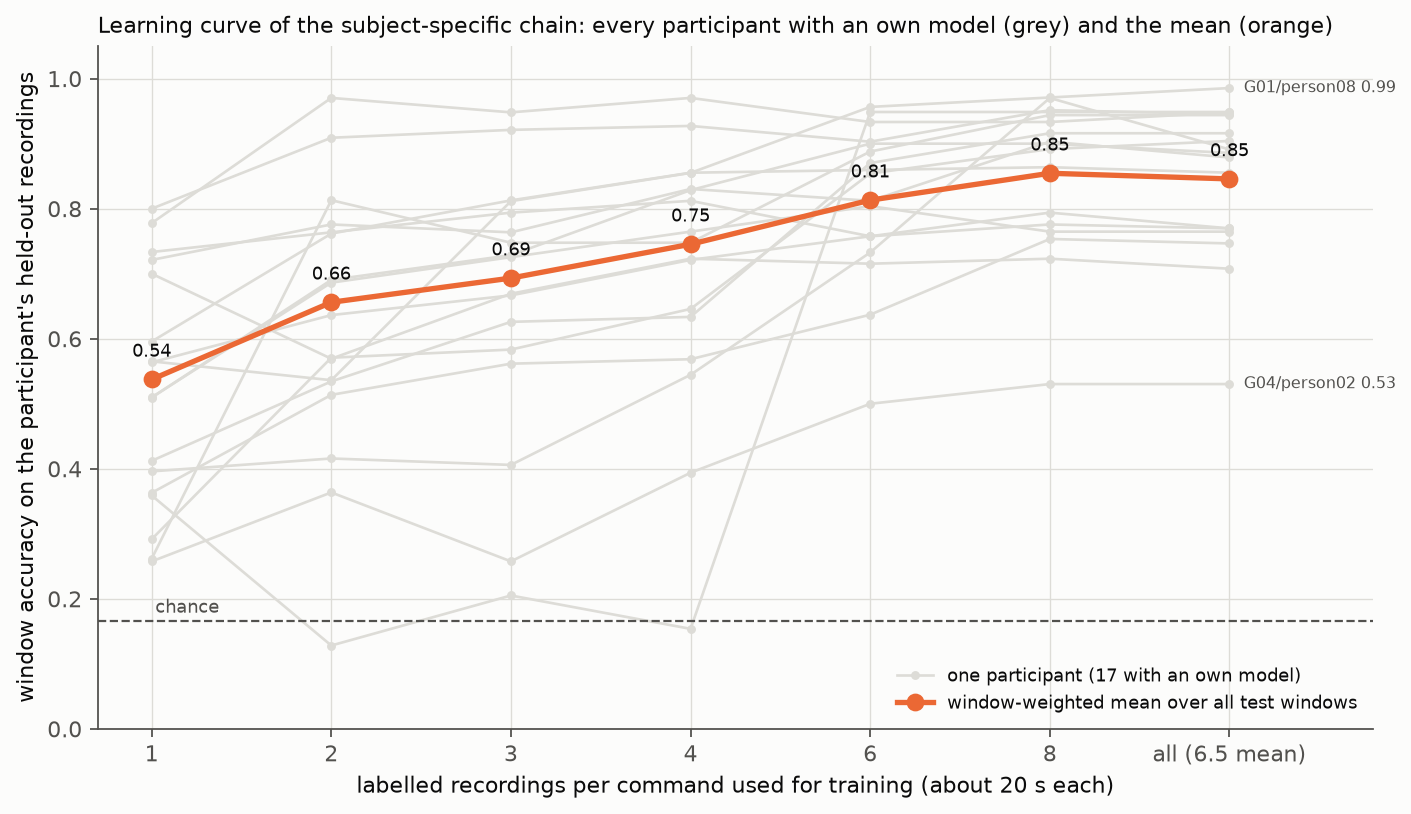

In [12]:
summary["learning_curve"] = M.learning_curve_spread(data, train, test)
show("defense_learning_curve_spread.png")

## Section 6.5: accuracy against the time distance to the nearest training window

Output: `defense_time_distance.png`, `defense_time_distance.csv` (why the notebook split cannot reveal the within-block drift).

[defense] wrote defense_time_distance.csv


[defense] wrote defense_time_distance.png


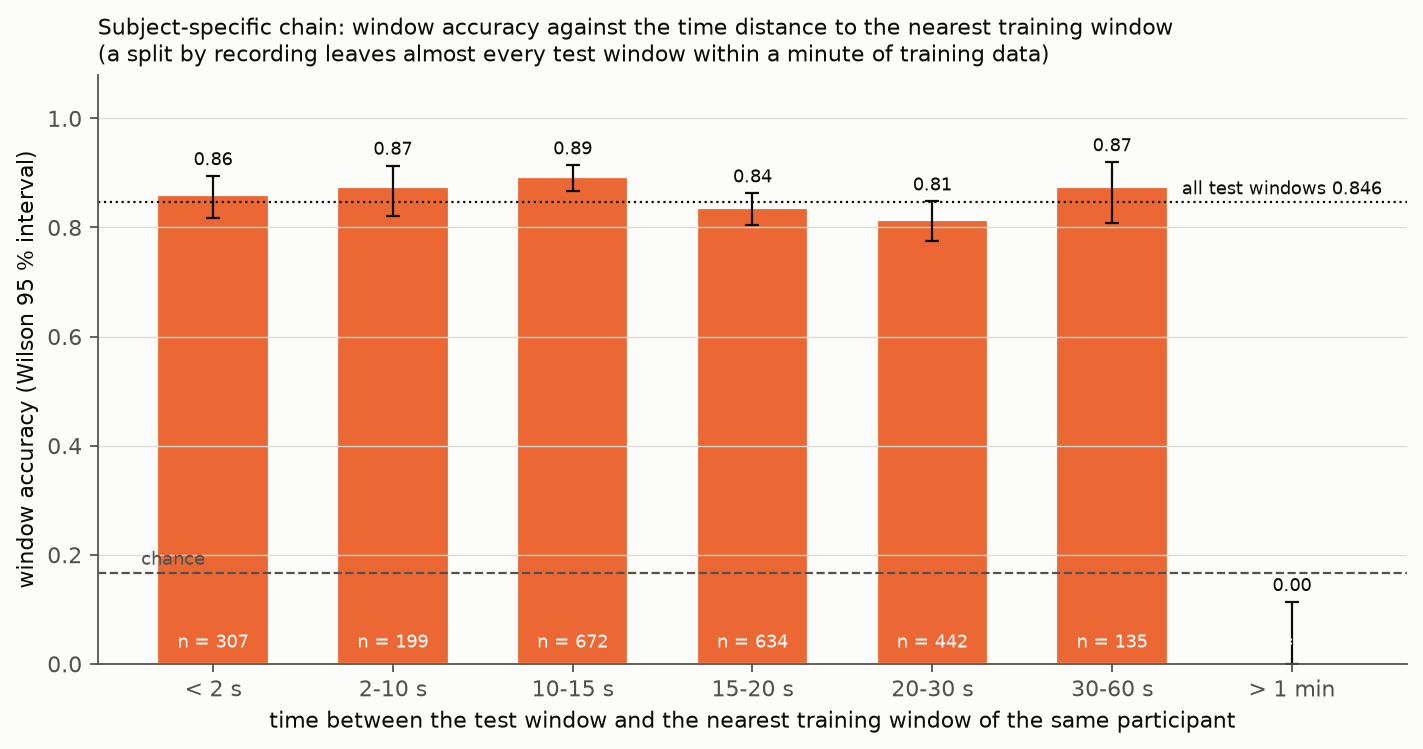

Gap to nearest training window,Windows,Accuracy,Wilson low,Wilson high
< 2 s,307,0.860,0.817,0.894
2-10 s,199,0.874,0.821,0.913
10-15 s,672,0.893,0.867,0.914
15-20 s,634,0.836,0.805,0.863
20-30 s,442,0.814,0.776,0.848
30-60 s,135,0.874,0.808,0.920
> 1 min,30,0.000,0.000,0.114


In [13]:
summary["time_distance"] = M.time_distance_figure(data, train, test, acc["pred_sub"])
show("defense_time_distance.png"); table("defense_time_distance.csv")

## Section 6.8: ablation and channel contribution

Outputs: `defense_subject_ablation.csv` (each feature group removed in turn; LDA restricted to 1 to 4 dimensions) and `defense_channel_contribution.csv` with `defense_channel_contribution.png` (absolute LDA loadings per channel over the 17 own models).

In [14]:
summary["subject_ablation"] = M.subject_ablation(data, train, test, chain_sub)
M.channel_contribution(chain_sub)
table("defense_subject_ablation.csv")

[defense] ablation all four groups, LDA 5 (deployed): 435 features, LDA 5: accuracy 0.8458 (5 s)


[defense] ablation without log-covariance 1-40 Hz: 315 features, LDA 5: accuracy 0.8115 (5 s)


[defense] ablation without log-covariance, first difference: 315 features, LDA 5: accuracy 0.8305 (5 s)


[defense] ablation without log-covariance 30-45 Hz: 315 features, LDA 5: accuracy 0.8322 (5 s)


[defense] ablation without multitaper band powers: 360 features, LDA 5: accuracy 0.8342 (5 s)


...

[defense] ablation all four groups, LDA 4: 435 features, LDA 4: accuracy 0.8222 (5 s)


[defense] wrote defense_subject_ablation.csv


[defense] wrote defense_channel_contribution.csv


[defense] wrote defense_channel_contribution.png (largest shares: EXG Channel 7, EXG Channel 12, EXG Channel 6)


Variant,Features,LDA dims,Accuracy,Macro-F1,Context-5 Acc,Per-recording Acc,Delta vs deployed
"all four groups, LDA 5 (deployed)",435,5,0.846,0.844,0.892,0.903,0.000
without log-covariance 1-40 Hz,315,5,0.811,0.808,0.860,0.852,-0.034
"without log-covariance, first difference",315,5,0.831,0.828,0.879,0.920,-0.015
without log-covariance 30-45 Hz,315,5,0.832,0.830,0.866,0.926,-0.014
without multitaper band powers,360,5,0.834,0.831,0.878,0.898,-0.012
"all four groups, LDA 1",435,1,0.549,0.544,0.597,0.631,-0.297
"all four groups, LDA 2",435,2,0.670,0.666,0.704,0.705,-0.176
"all four groups, LDA 3",435,3,0.763,0.762,0.808,0.835,-0.083
"all four groups, LDA 4",435,4,0.822,0.821,0.863,0.898,-0.024


## Figure 6.7: one participant's own discriminant axes against the global LDA

Output: `defense_lda_scatter.png` (G03/person03's 210 held-out windows through the stored projections of both chains).

[defense] wrote defense_lda_scatter.png (G03/person03: own LDA 0.886, global LDA 0.510 on 210 windows)


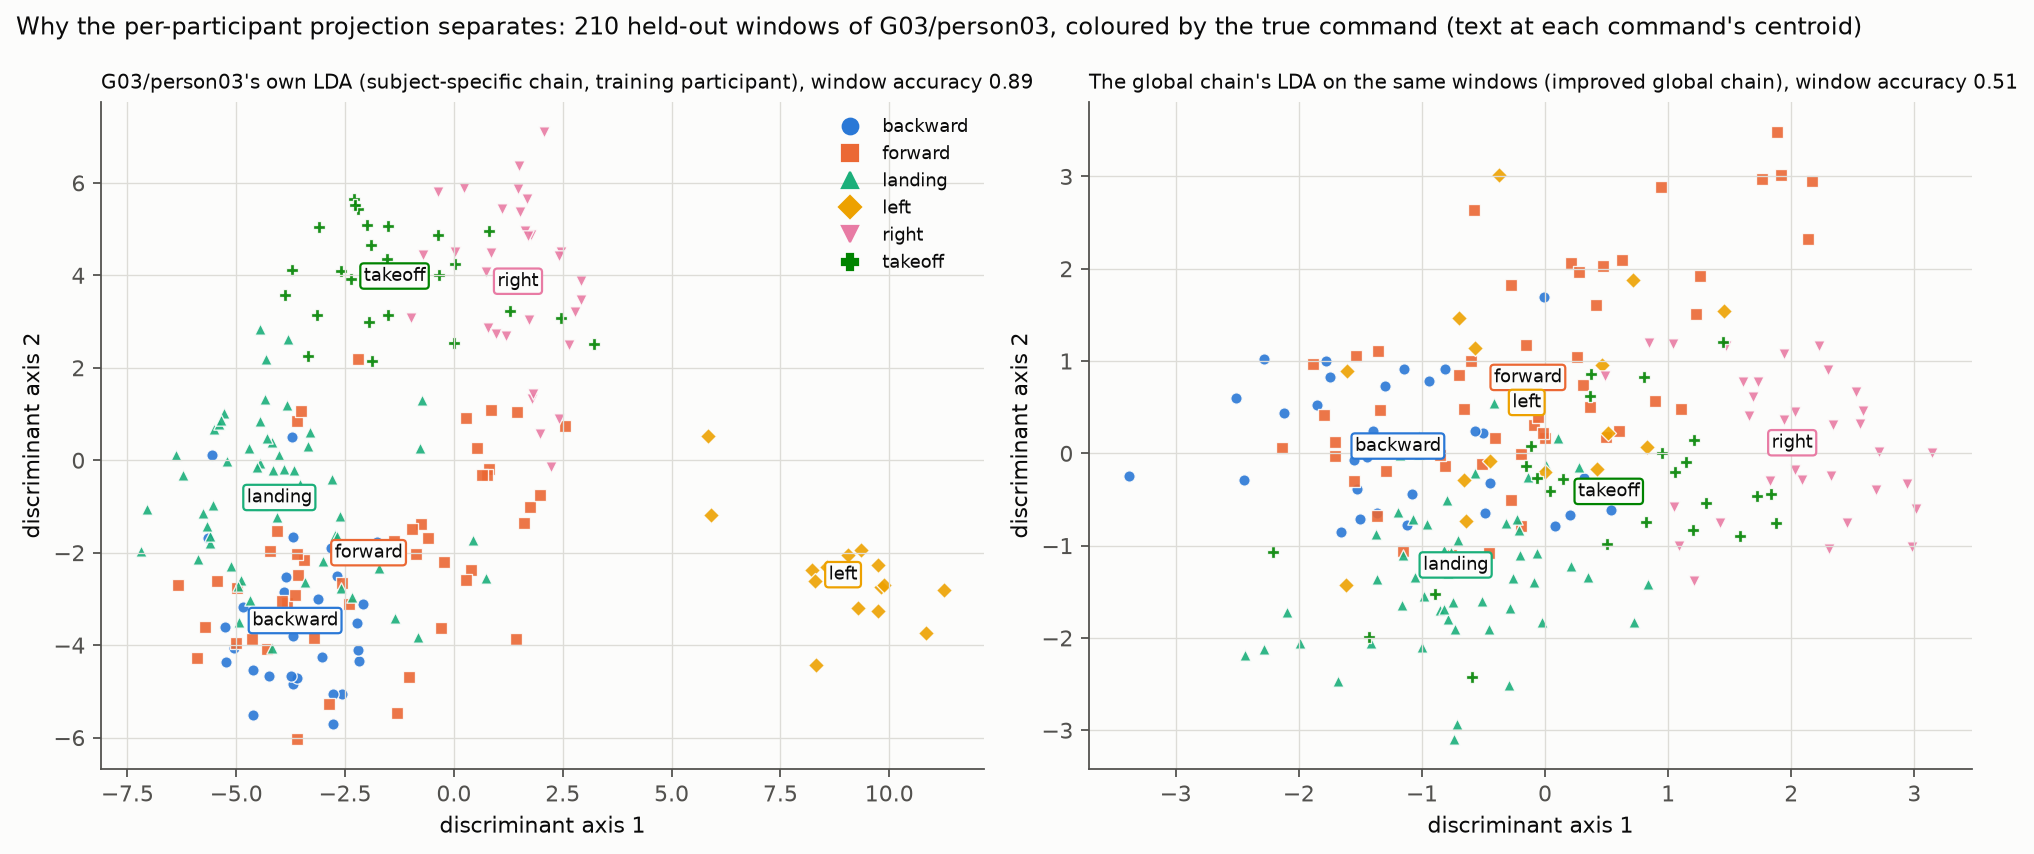

In [15]:
summary["lda_scatter"] = M.lda_scatter(data, test, chain_imp, chain_sub)
show("defense_lda_scatter.png")

## Figure 6.8: decision timeline of the subject-specific chain

Output: `defense_decision_timeline.png` (one held-out recording per command of G03/person03, concatenated in time).

[defense] wrote defense_decision_timeline.png (6 recordings, 85 windows, window accuracy 0.859, 46/61 decisions accepted at 1.000)


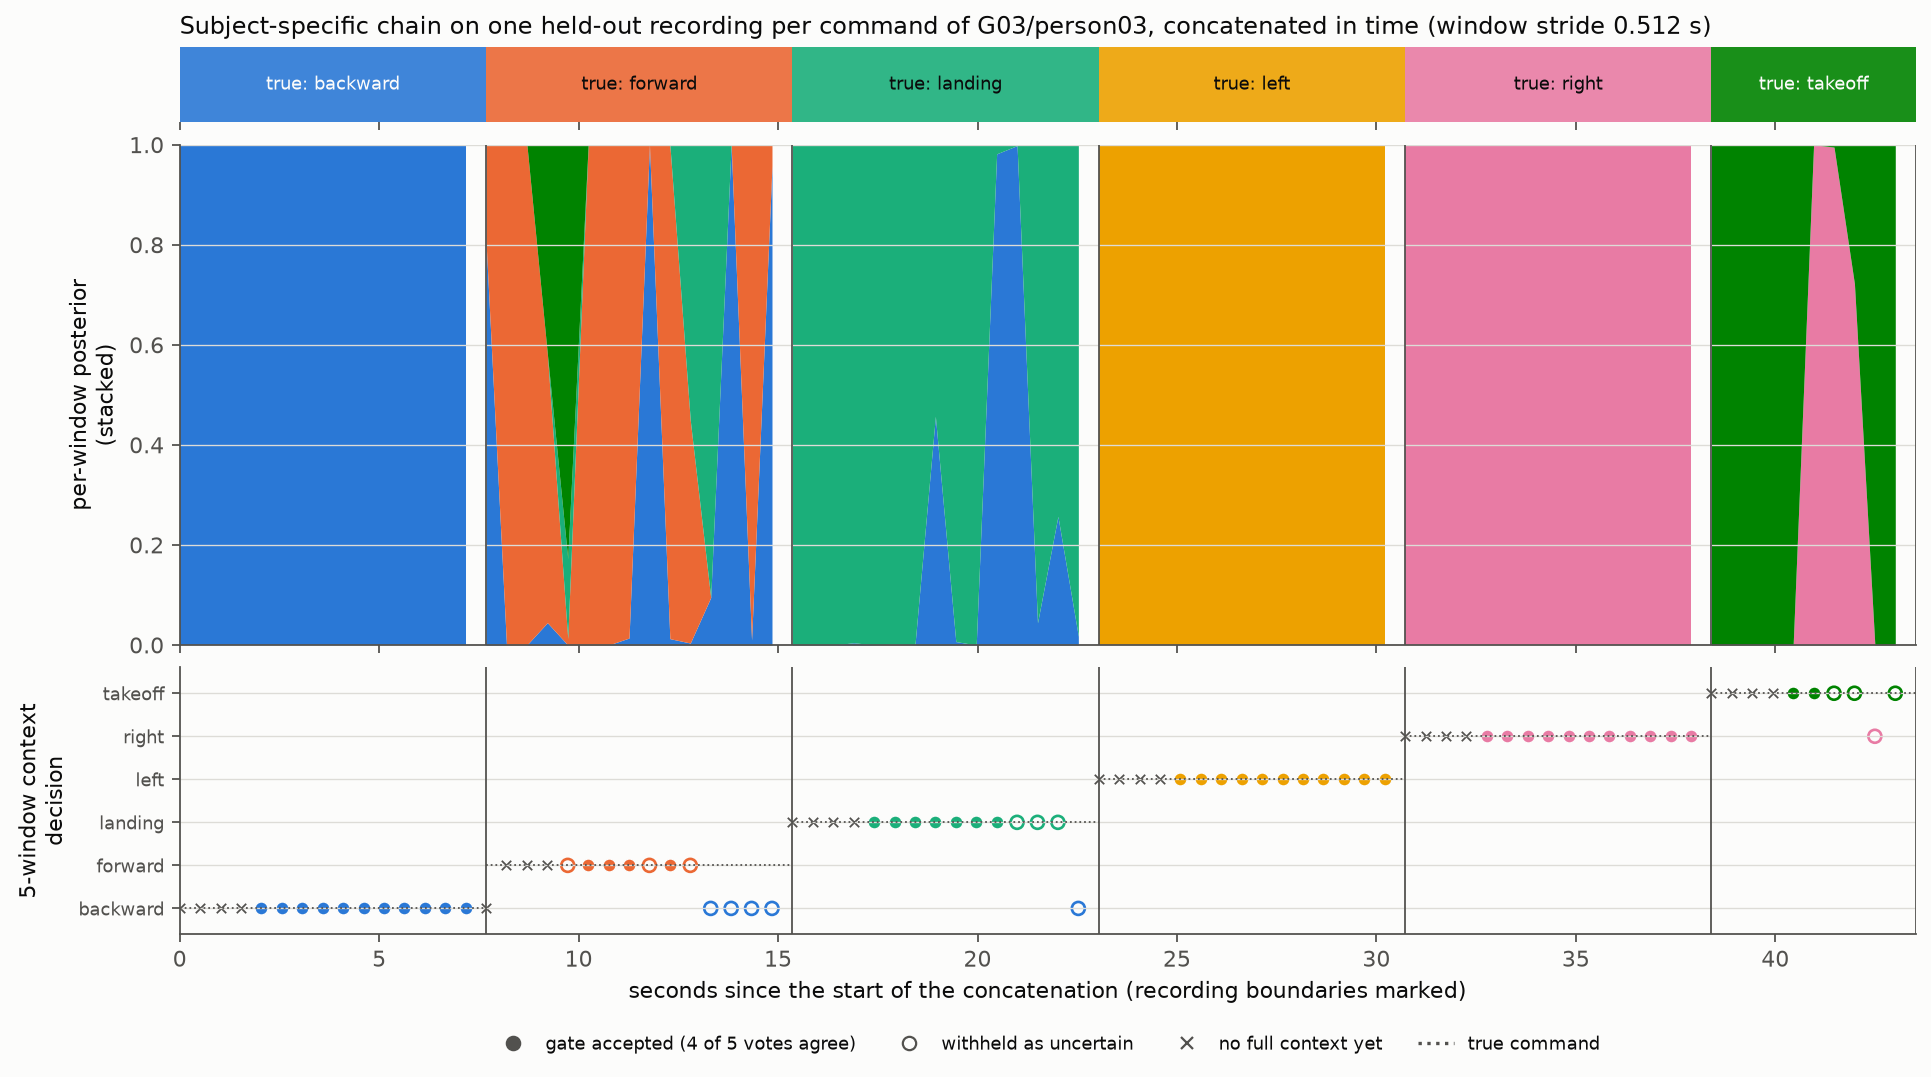

In [16]:
summary["decision_timeline"] = M.decision_timeline(data, test, logp_sub)
show("defense_decision_timeline.png")

## Figure 5.2: posterior margin and vote count for right and wrong decisions

Output: `defense_confidence.png` (why the gate uses votes, not posteriors).

[defense] wrote defense_confidence.png


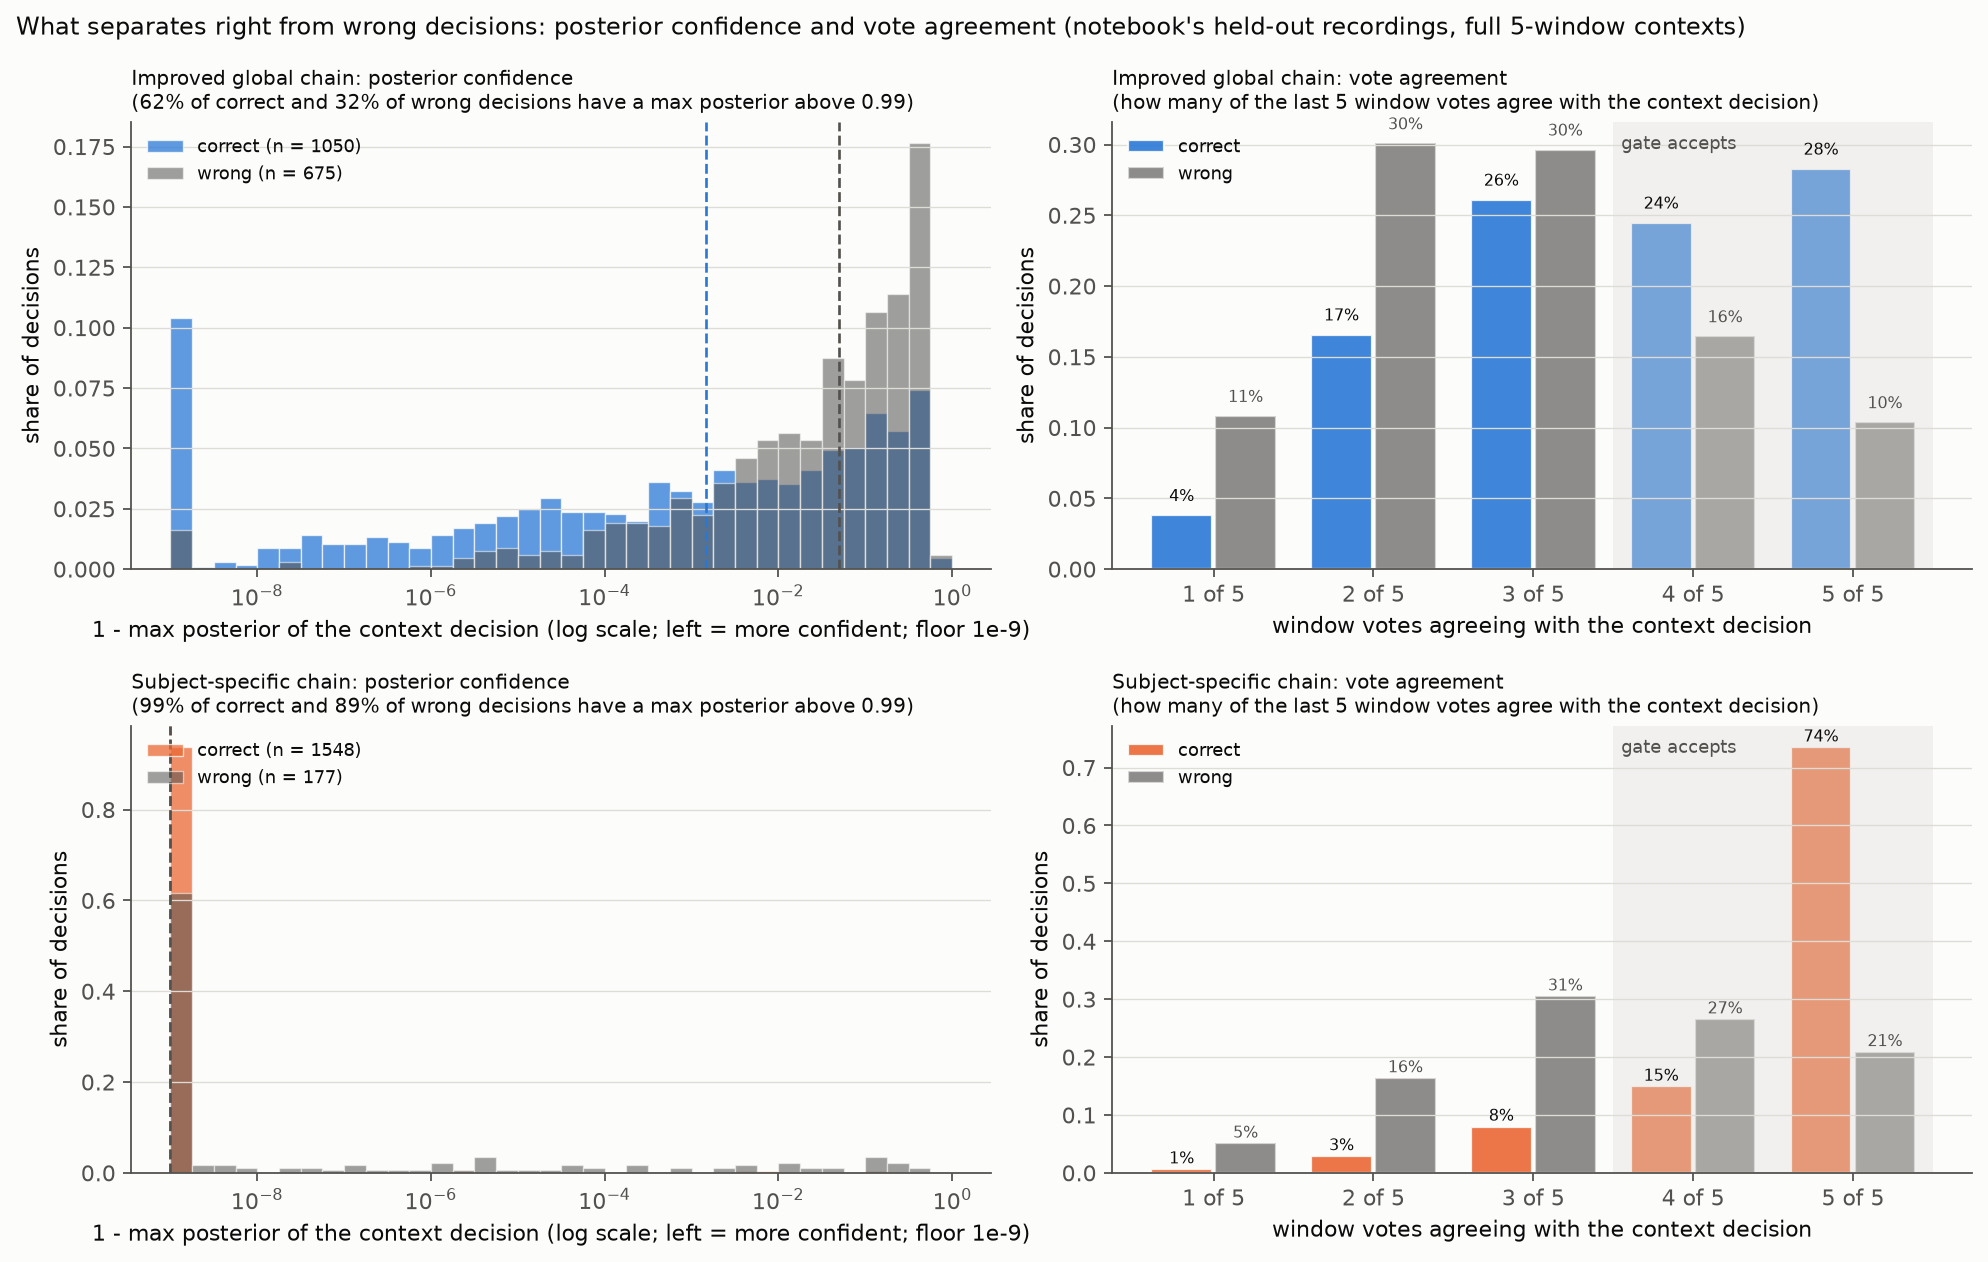

In [17]:
summary["confidence"] = M.confidence_figure(data, test, logp_by_chain)
show("defense_confidence.png")

## Table 8.1, Table 8.2 and Table 6.2: the three frameworks' equivalence, window geometry and notebook protocol numbers

Outputs: `defense_framework_equivalence.csv` (identical decisions on the same stored arrays; agreement when fitted separately) and `defense_framework_notebooks.csv` (each notebook's protocol A and C numbers with its window geometry, the source of the held-out-participant table).

In [18]:
equiv, nb_frameworks, geo = M.framework_equivalence(data, train, test, chain_sub)
summary["framework_equivalence"] = equiv.to_dict("records")
display(table("defense_framework_equivalence.csv", "{:.4f}")); display(geo); table("defense_framework_notebooks.csv")

I0000 00:00:1792210059.597949   25376 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792210060.749881   25376 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


[defense] wrote defense_framework_equivalence.csv


[defense] framework equivalence over 17 participants with own models


[defense] wrote defense_framework_notebooks.csv


Comparison,Windows,Decision agreement,Max |difference in class probability|,Accuracy PyTorch,Accuracy other
"PyTorch vs TensorFlow, same stored model arrays",2389,1.0000,0.0000,nan,nan
"PyTorch vs JAX, same stored model arrays",2389,1.0000,0.0000,nan,nan
"PyTorch vs TensorFlow, separately fitted on the same training windows",2389,0.9987,nan,0.8564,0.8560
"PyTorch vs JAX, separately fitted on the same training windows",2389,0.9987,nan,0.8564,0.8560


,Framework,window_size,window_stride,capture_samples,capture_seconds,global_decision,subject_window_size
0,PyTorch,128,64,384,3.07,per-class thresholds,128
1,TensorFlow,125,62,373,2.98,argmax,125
2,JAX,125,50,325,2.60,argmax,125


Framework,Chain,Protocol,Window_accuracy,File_accuracy,window_size,window_stride,capture_samples
PyTorch,improved global chain,5-fold by recording (seed 42),0.489,0.625,128,64,384
PyTorch,improved global chain,5-fold by participant,0.184,0.184,128,64,384
PyTorch,subject-specific chain,5-fold by recording (seed 42),0.843,0.900,128,64,384
PyTorch,subject-specific chain,5-fold by participant,0.189,0.194,128,64,384
TensorFlow,improved global chain,5-fold by recording (seed 42),0.493,0.608,125,62,373
TensorFlow,subject-specific chain,5-fold by recording (seed 42),0.840,0.891,125,62,373
TensorFlow,improved global chain,5-fold by participant (held-out people),0.185,0.180,125,62,373
TensorFlow,subject-specific chain,5-fold by participant (held-out people),0.184,0.181,125,62,373
JAX,improved global chain,5-fold by recording (seed 42),0.491,0.600,125,50,325
JAX,subject-specific chain,5-fold by recording (seed 42),0.839,0.896,125,50,325


## Figure 8.1, Figure 8.2 and Table 8.3: performance of the best chain across PyTorch, TensorFlow and JAX

Outputs: `defense_framework_performance.png` (accuracy, macro-F1, balanced accuracy and Cohen's kappa per framework, and the per-command F1), `defense_framework_confusion_matrices.png` (one confusion matrix per framework) and `defense_framework_performance.csv`. The subject-specific chain is fitted separately in each framework on the same training windows and scored on the same 2,389 test windows, so the only difference between the three is the implementation; the notebooks' own protocol A numbers are appended.

[defense] wrote defense_framework_performance.csv


[defense] framework performance: PyTorch acc 0.8564 F1 0.8546, TensorFlow acc 0.8560 F1 0.8541, JAX acc 0.8560 F1 0.8541


[defense] wrote defense_framework_performance.png


[defense] wrote defense_framework_confusion_matrices.png


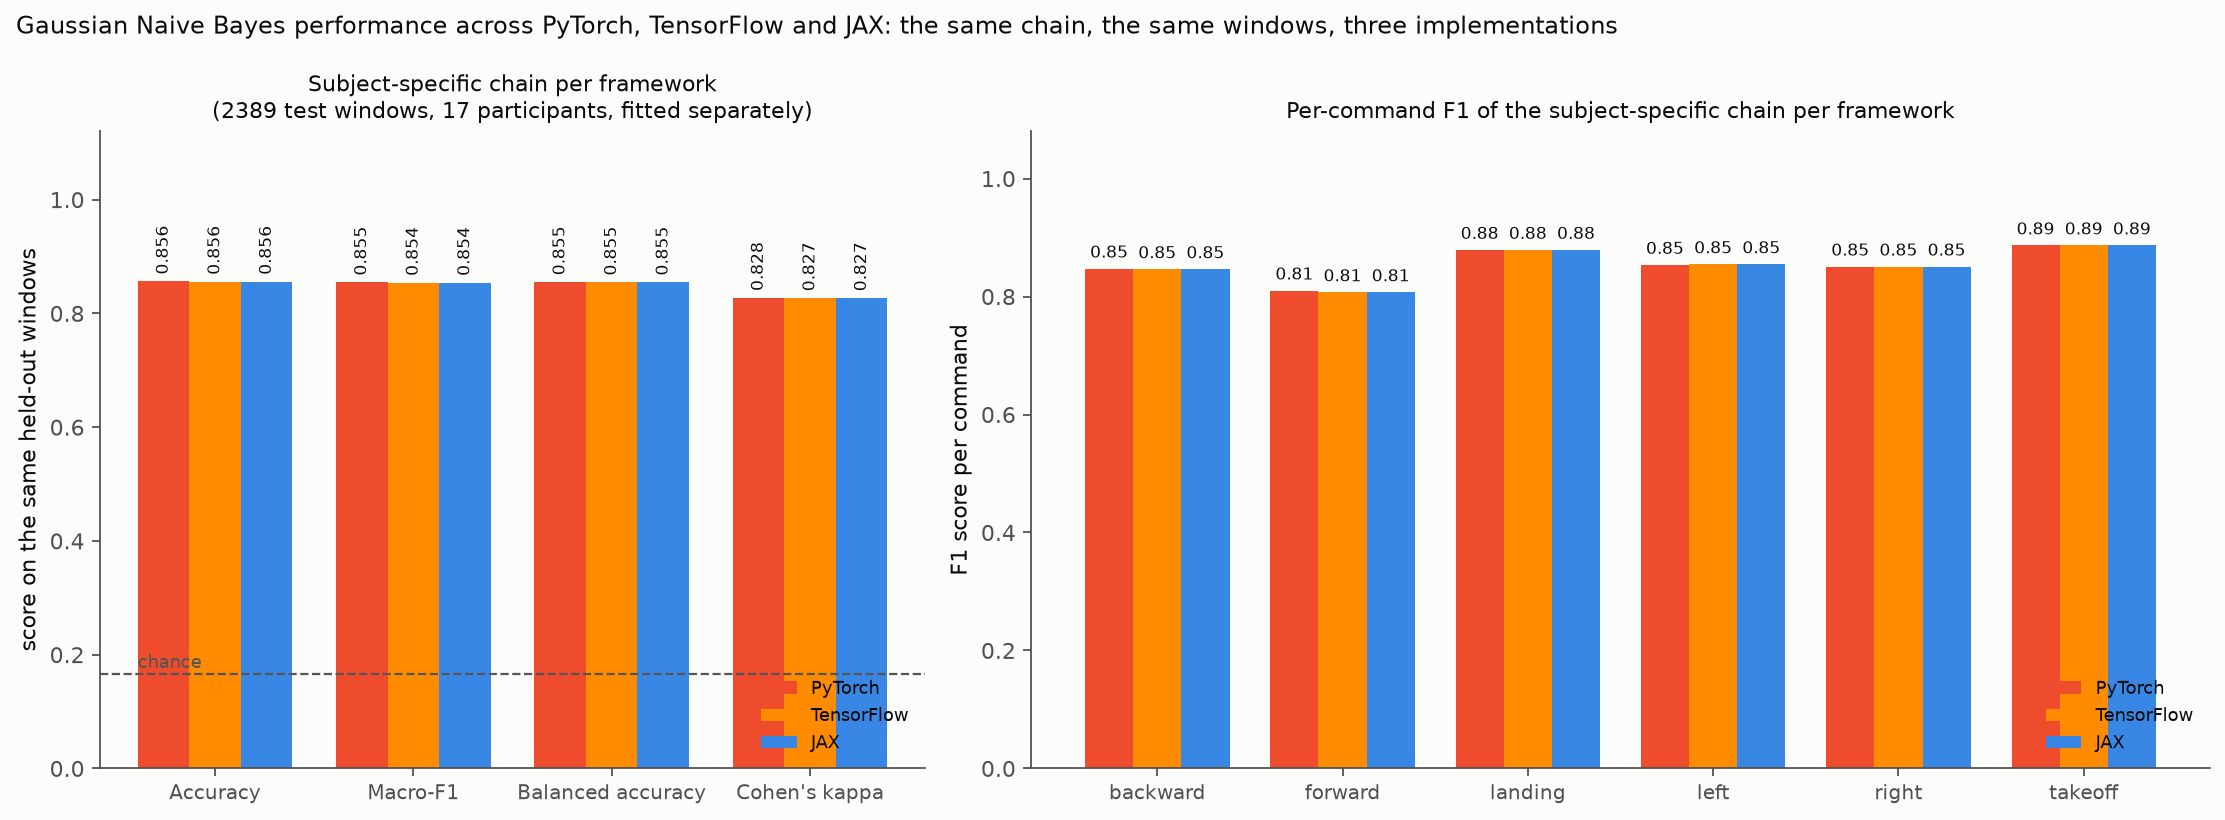

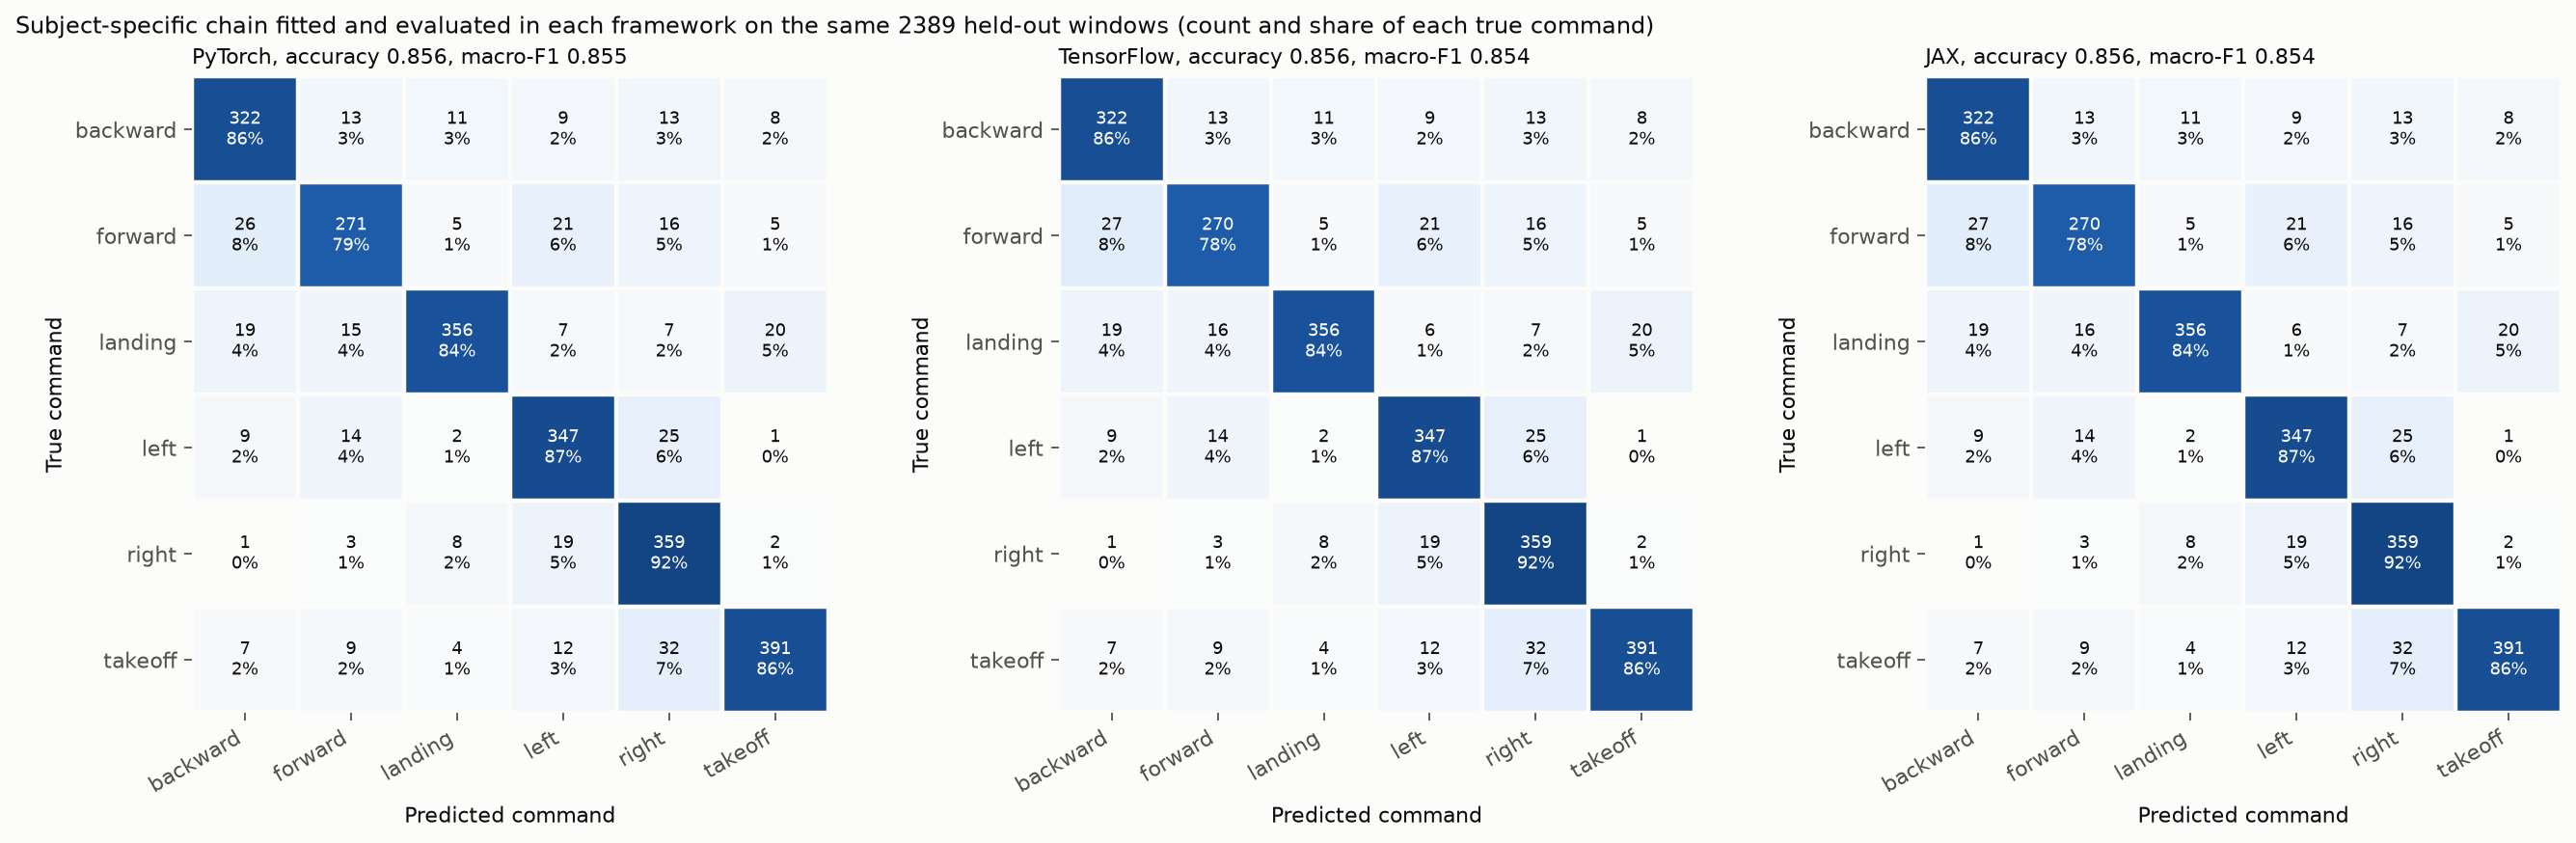

Framework,Chain,Windows,Participants,Accuracy,Macro-F1,Balanced accuracy,Cohen's kappa,Agreement with PyTorch,F1 backward,F1 forward,F1 landing,F1 left,F1 right,F1 takeoff,Notebook protocol A window accuracy,Notebook protocol A per-recording accuracy,Notebook window size,Notebook window stride
PyTorch,subject-specific chain,2389,17,0.856,0.855,0.855,0.828,1.000,0.847,0.810,0.879,0.854,0.851,0.887,0.843,0.900,128,64
TensorFlow,subject-specific chain,2389,17,0.856,0.854,0.855,0.827,0.999,0.846,0.807,0.879,0.855,0.851,0.887,0.840,0.891,125,62
JAX,subject-specific chain,2389,17,0.856,0.854,0.855,0.827,0.999,0.846,0.807,0.879,0.855,0.851,0.887,0.839,0.896,125,50


In [19]:
fwperf = M.framework_performance(data, train, test, chain_sub, nb_frameworks)
summary["framework_performance"] = fwperf.to_dict("records")
show("defense_framework_performance.png"); show("defense_framework_confusion_matrices.png"); table("defense_framework_performance.csv")

## Table 9.1: model complexity and artifact sizes

Output: `defense_model_complexity.csv` (the last column of the benchmark table; the benchmark itself is cell 36 of the main notebook, `../pytorch/final_model_benchmark_project_models_summary.csv`).

In [20]:
summary["model_complexity"] = M.model_complexity(data, train, chain_imp, chain_sub)
table("defense_model_complexity.csv")

[defense] wrote defense_model_complexity.csv


[defense] one user's model fits in 269 ms (median of 20)


Model,Stage,Parameters,Artifact,Size on disk (KB),Note
Improved global chain,participant z-score (18 participants + global),21660.000,torch_gaussiannb_participant_scaler.joblib,171.600,mean and std of 570 features; a new user adds 1140 from a calibration recording
Improved global chain,LDA projection (570 -> 5),2850.000,torch_gaussiannb_preprocessing.joblib,5131.300,the fitted sklearn LDA also stores two 570 x 570 matrices the live chain never uses
Improved global chain,GaussianNB (6 classes x 5 dims) + thresholds,72.000,torch_gaussiannb_improved_features.pth,25.800,"priors, means, variances, per-class thresholds"
Improved global chain,total,24582.000,three files,5328.700,the 5.1 MB is the sklearn LDA object; the projection itself is 23 KB
Subject-specific chain,one user's z-score,870.000,torch_gaussiannb_subject_scaler.joblib,131.800,the artifact holds 18 participants + global
Subject-specific chain,one user's LDA projection (435 -> 5),2175.000,torch_gaussiannb_subject_models.joblib,323.600,the artifact holds 17 own models + the global fallback
Subject-specific chain,one user's GaussianNB (6 classes x 5 dims),66.000,torch_gaussiannb_subject_models.joblib,nan,"priors, means, variances"
Subject-specific chain,total per user,3111.000,model.npz per user in the GUI's store,nan,all 18 models + scaler: 455.4 KB
Subject-specific chain,fit of one user's model (631 windows of G03/person03),nan,nan,nan,"median 269 ms over 20 fits (p90 303 ms): z-score, LDA, GaussianNB"
RandomForest (PyTorch notebook),saved artifact,nan,prediction-random-forest/pytorch/custom_rf.pt.gz,8387.100,gzip-compressed state; parameters not counted (not loaded here)


## Supplementary outputs (not printed in the paper)

Per-recording confusion matrices, the gated confusion matrices with the withheld column, and the one-versus-rest average precision and ROC AUC of the deployed chains: `defense_per_recording_confusion_matrices.png`, `defense_gated_confusion_matrices.png`, `defense_gated_confusion_matrix.csv`, `defense_deployed_pr_roc.csv`.

In [21]:
summary["per_recording"] = M.per_recording_confusions(data, test, logp_by_chain)
summary["gated"] = M.gated_confusions(data, test, logp_by_chain)
summary["deployed_pr_roc"] = M.deployed_pr_roc(data, test, logp_by_chain)
table("defense_deployed_pr_roc.csv")

[defense] Improved global chain: per-recording accuracy 0.6250 over 176 recordings


[defense] Subject-specific chain: per-recording accuracy 0.9034 over 176 recordings


[defense] wrote defense_per_recording_confusion_matrices.png


[defense] wrote defense_gated_confusion_matrix.csv


[defense] wrote defense_gated_confusion_matrix.png


[defense] wrote defense_deployed_pr_roc.csv


[defense] wrote defense_deployed_pr_roc.png


Chain,Class,Average precision,ROC AUC,Support,Prevalence (AP of a random scorer)
Improved global chain,backward,0.527,0.856,376,0.155
Improved global chain,forward,0.382,0.710,374,0.155
Improved global chain,landing,0.625,0.850,424,0.175
Improved global chain,left,0.452,0.817,398,0.165
Improved global chain,right,0.542,0.827,392,0.162
Improved global chain,takeoff,0.584,0.824,455,0.188
Improved global chain,macro,0.519,0.814,2419,0.167
Subject-specific chain,backward,0.928,0.978,376,0.155
Subject-specific chain,forward,0.885,0.973,374,0.155
Subject-specific chain,landing,0.950,0.986,424,0.175


## Section 8.4: latency of the decision models alone

Output: `defense_decision_model_latency.csv` (first fit, second fit, first prediction and steady-state prediction per model and device; median of 200 timed calls). Timings vary from run to run and machine to machine; the paper quotes the values in the CSV as committed.

In [4]:
dm = M.bench_decision_models()
summary["decision_model_latency"] = dm.to_dict("records")
table("defense_decision_model_latency.csv")

I0000 00:00:1792211248.565571   31351 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792211249.887661   31351 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


[defense] wrote defense_decision_model_latency.csv


Model,Device,n_train,first_fit_ms,second_fit_ms,first_predict_ms,steady_predict_ms,steady_predict_p90_ms
PyTorch GaussianNB,CPU,600,0.714,0.406,0.506,0.051,0.059
PyTorch GaussianNB,CUDA,600,57.608,1.158,37.790,0.106,0.119
TensorFlow GaussianNBTF,CPU,600,38.098,1.841,7.256,1.016,1.249
JAX GaussianNBJAX,CPU,600,524.837,1.568,77.882,0.210,0.221
PyTorch GaussianNB,CPU,9670,1.156,0.892,0.123,0.049,0.051
PyTorch GaussianNB,CUDA,9670,1.313,1.122,0.169,0.108,0.119
TensorFlow GaussianNBTF,CPU,9670,2.743,1.978,1.235,1.007,1.074
JAX GaussianNBJAX,CPU,9670,283.868,1.692,0.348,0.211,0.234
JAX GaussianNBJAX,GPU,600,1007.002,4.561,134.525,0.459,1.105
JAX GaussianNBJAX,GPU,9670,589.170,3.630,0.552,0.499,0.588


## Table 8.4 and Figure 8.3: latency of one live capture per chain and framework

Outputs: `defense_latency_per_capture.csv`, `defense_latency_per_capture.png` (one real Data_clean capture of G03/person03 through each chain on the CPU, median of 50 after warm-up, split into signal-to-features and features-to-decision).

[defense] Improved global chain / PyTorch: 3.9 ms per capture


[defense] Subject-specific chain / PyTorch: 4.4 ms per capture


[defense] Improved global chain / TensorFlow: 4.6 ms per capture


[defense] Subject-specific chain / TensorFlow: 5.6 ms per capture


[defense] Improved global chain / JAX: 3.7 ms per capture


[defense] Subject-specific chain / JAX: 4.6 ms per capture


[defense] wrote defense_latency_per_capture.csv


[defense] wrote defense_latency_per_capture.png


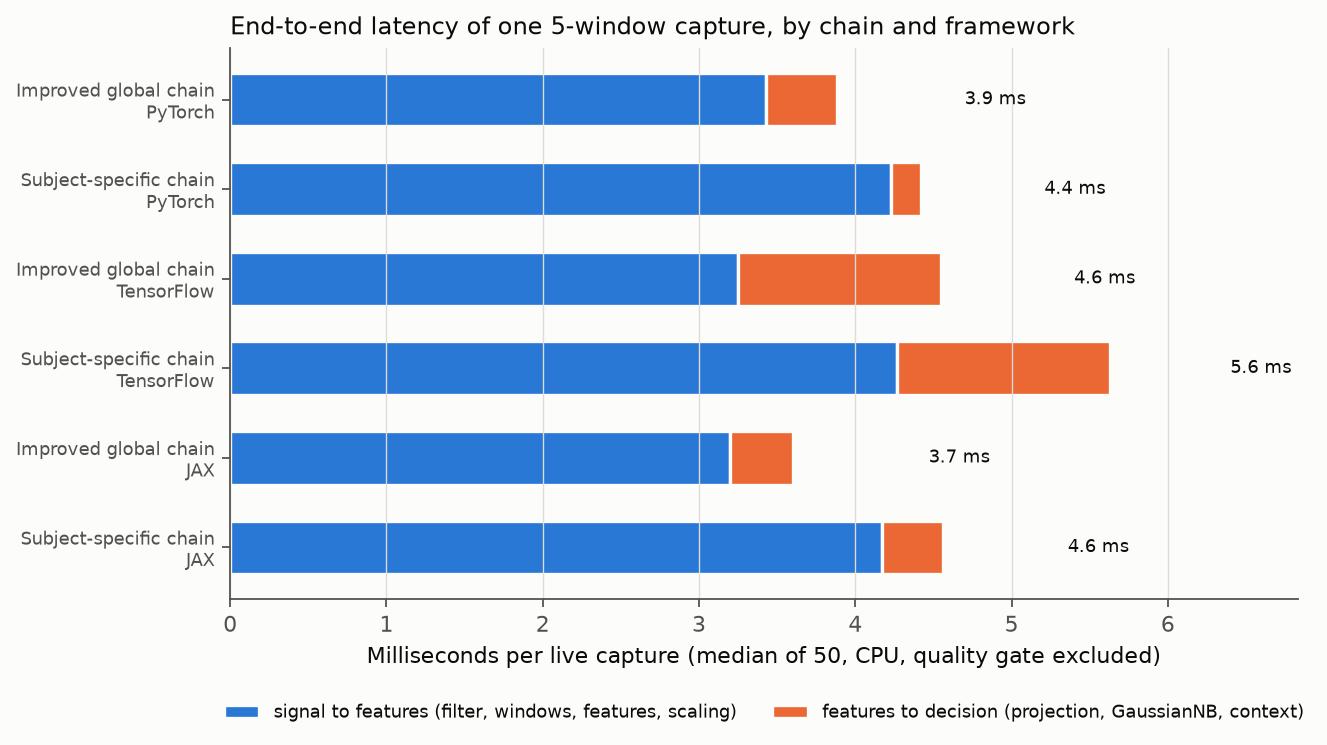

Chain,Framework,Capture samples,Capture seconds,Windows,Features,Signal to features ms,Features to decision ms,Total ms (median),Total ms (p90)
Improved global chain,PyTorch,384,3.070,5,570,3.430,0.450,3.900,3.990
Subject-specific chain,PyTorch,384,3.070,5,435,4.230,0.190,4.410,4.610
Improved global chain,TensorFlow,373,2.980,5,570,3.250,1.300,4.600,4.650
Subject-specific chain,TensorFlow,373,2.980,5,435,4.270,1.360,5.600,6.060
Improved global chain,JAX,325,2.600,5,570,3.200,0.400,3.670,3.780
Subject-specific chain,JAX,325,2.600,5,435,4.170,0.390,4.560,4.680


In [5]:
ch = M.bench_chains(data)
summary["latency_per_capture"] = ch.to_dict("records")
show("defense_latency_per_capture.png"); table("defense_latency_per_capture.csv")

## Figure 9.1 and Table 9.1: the best GNB model per framework against the project's original random forest and MLP, run as written, under three data splits

Outputs: `defense_project_models_benchmark.png`, `defense_project_models_benchmark.csv` (means) and `defense_project_models_benchmark_runs.csv` (every run). The best GNB model, the subject-specific chain, is refitted in PyTorch, TensorFlow and JAX on the same six hold-outs as the comparison; the JAX random forest (`prediction-random-forest/JAX/jax_random_forest.py`) and the JAX MLP (`prediction_deep_learning/JAX/deep_learning_jax.py`) are imported from their own files and run with their own hyperparameters, loader and seeds: (1) as reported, with their own loader on the BrainFlow CSV exports of Data_clean and their own random split of rows, next to the accuracies stored in the project's pickles; (2) the same rows split by recording; (3) the verified windows with the 570 chain features under the six recording-grouped hold-outs of the GNB benchmark (`../pytorch/final_model_benchmark_project_models_summary.csv`, cell 36 of the main notebook). The old scripts' misspelled folder labels are mapped to the six commands. Because the original forest trains at about one tree per 20 s on 20,000 rows, conditions 1 and 2 use a random 30,000-row subsample of the loader's 291,200 rows (every file keeps rows, so both the random-row leak and the split by file are preserved); the fits run in four worker processes on the CPU. Needs flax and optax; the slowest section of this notebook.

[defense] stored test accuracies in the project's pickles: {'JAX random forest': 0.9436305070656692, 'JAX deep learning (MLP)': 0.9359673857688904}


[defense] folder labels mapped to the six commands: B ackward -> backward, Foreward -> forward, Fowward -> forward, TakOff -> takeoff, backard -> backward


[defense] old loader: 291,200 rows of 32 columns from 1820 BrainFlow exports (16 s); using 30,000 rows of 1820 files


[defense] 16 fits of the original models in 4 worker processes (the forest is the slow part)


[defense] GNB subject chain (PyTorch), seed 0: accuracy 0.8537, macro-F1 0.8548


...

[defense] JAX random forest, 3. seed 5: accuracy 0.5068, macro-F1 0.4995 in 117 s


[defense] JAX deep learning (MLP), 3. seed 5: accuracy 0.6901, macro-F1 0.6833 in 16 s


[defense] wrote defense_project_models_benchmark_runs.csv


[defense] wrote defense_project_models_benchmark.csv


[defense] wrote defense_project_models_benchmark.png in 643 s


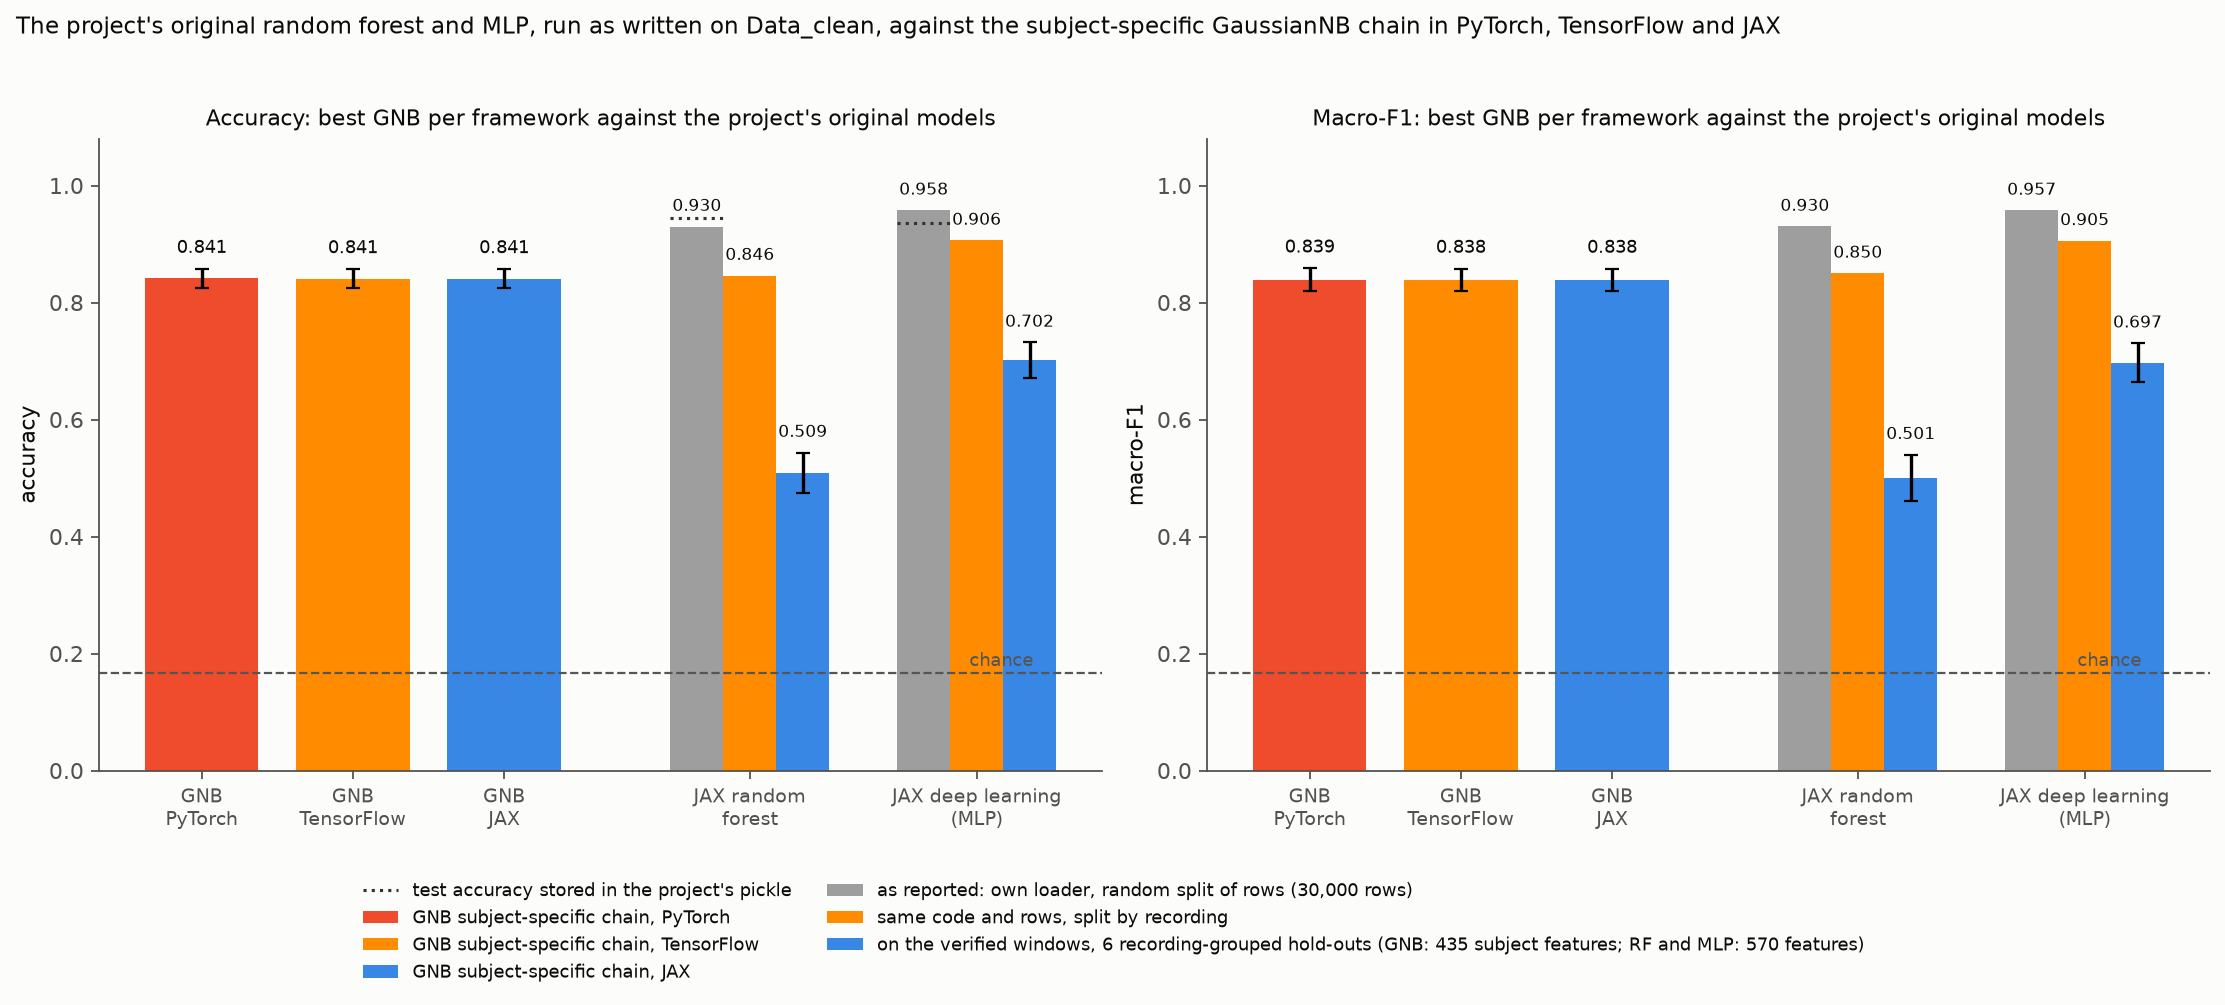

Model,Condition,runs,Accuracy,Accuracy_sd,Macro-F1,Macro-F1_sd,Balanced accuracy,Reported,n_train,n_test,seconds,rows_in_loader,files_in_loader,rows_used
GaussianNB subject-specific chain (PyTorch),"3. same code on the verified windows (570 features), split by recording",6,0.841,0.016,0.839,0.019,0.841,nan,9672.333,2416.667,5.171,291200,1820,30000
GaussianNB subject-specific chain (TensorFlow),"3. same code on the verified windows (570 features), split by recording",6,0.841,0.016,0.838,0.019,0.841,nan,9672.333,2416.667,5.414,291200,1820,30000
GaussianNB subject-specific chain (JAX),"3. same code on the verified windows (570 features), split by recording",6,0.841,0.016,0.838,0.019,0.841,nan,9672.333,2416.667,16.798,291200,1820,30000
JAX random forest,"1. as reported: own loader, random split of rows",1,0.930,nan,0.930,nan,0.930,0.944,21000.000,6000.000,409.353,291200,1820,30000
JAX deep learning (MLP),"1. as reported: own loader, random split of rows",1,0.958,nan,0.957,nan,0.957,0.936,21000.000,6000.000,29.293,291200,1820,30000
JAX random forest,"2. same code and rows, split by recording",1,0.846,nan,0.850,nan,0.851,nan,24055.000,5945.000,458.172,291200,1820,30000
JAX deep learning (MLP),"2. same code and rows, split by recording",1,0.906,nan,0.905,nan,0.908,nan,24055.000,5945.000,29.400,291200,1820,30000
JAX random forest,"3. same code on the verified windows (570 features), split by recording",6,0.509,0.035,0.501,0.039,0.506,nan,9672.333,2416.667,120.956,291200,1820,30000
JAX deep learning (MLP),"3. same code on the verified windows (570 features), split by recording",6,0.702,0.030,0.697,0.033,0.699,nan,9672.333,2416.667,13.289,291200,1820,30000


In [4]:
pmb = M.project_models_benchmark(data)
summary["project_models_benchmark"] = pmb.to_dict("records")
show("defense_project_models_benchmark.png"); table("defense_project_models_benchmark.csv")

## Markdown tables and the summary file

`defense_tables.md` holds every CSV as a markdown table; `defense_summary.json` holds the numbers returned by each function.

In [5]:
M.write_tables_md()
(HERE / "defense_summary.json").write_text(json.dumps(summary, indent=2, default=M.json_default))
print(f"done in {time.perf_counter() - t_start:.0f} s")

done in 643 s
